# Clinical TabReD
## Evaluating Tabular Machine Learning Models under Temporal Distribution Shift in Healthcare Data

**Course:** CSCI 447 Machine Learning: Theory and Practice, Fall 2026
**Project ID:** P034
**Students:**
Nurbek Baktygali (202127847)  
Yelzhan Rakhimzhanov (202197093)
**Instructor:** Dr. Hari Mohan Rai, Assistant Professor, Department of Computer Science, SCAI, Nazarbayev University

This notebook is the complete experimental procedure of the project: a **clinical version of the
TabReD benchmark** (Rubachev et al., 2024) built from three public US health data sources,
NHANES 2005-2018, BRFSS 2017-2023 and NCHS natality 2016-2024. It covers data loading,
preprocessing and leakage checks, exploratory analysis, the TabReD split design, training of five
models, cross-validation, evaluation with bootstrap confidence intervals, a drift analysis in which
each drift is linked to its clinical cause, and the results.

**How to run.** The notebook must be run from the `notebooks/` folder of the project repository
(it reads the processed tables in `data/processed/` and the saved results in `results_<dataset>/`).
* `RUN_EXPERIMENTS = False` (default, ~15 min on a 16-core CPU): uses the saved benchmark results,
  and **re-trains the selected configuration of every model on the default split of every dataset**
  to show that the saved numbers are reproduced. All tables and figures are recomputed from the
  saved predictions.
* `RUN_EXPERIMENTS = True` (~3 h): re-runs hyperparameter tuning on all 7 splits, 5-fold CV and the
  drift analysis for all three datasets, overwriting `results_<dataset>/`.
* `REBUILD_TABLES = True`: rebuilds the processed tables from the raw CDC/NCHS files (needs the raw
  files in `data/raw/`, ~2.6 GB, see the repository README).

All code in this notebook is copied automatically from the repository (`scripts/build_notebook.py`),
so the notebook runs exactly the code that produced the reported results.

In [1]:
RUN_EXPERIMENTS = False   # True: re-run the full benchmark, CV and drift analysis (~3 h, overwrites results)
REBUILD_TABLES = False    # True: rebuild the processed tables from the raw files in data/raw/

In [2]:
%matplotlib inline
import copy
import importlib
import inspect
import itertools
import json
import logging
import os
import platform
import subprocess
import sys
import time
from importlib import metadata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Code, Image, Markdown, display
from lightgbm import LGBMClassifier
from matplotlib import font_manager
from scipy.stats import ks_2samp
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, log_loss,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

# Repository root: the folder that contains configs/experiment.yaml (the notebook lives in notebooks/).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "experiment.yaml").exists())
NB_OUT = ROOT / "notebooks" / "outputs"          # tables and figures written by this notebook
SUMMARY_DIR = NB_OUT / "tables"
FIGURES_DIR = NB_OUT / "figures"
FORMATS = ("png",)
for d in (SUMMARY_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "scripts"))        # only used to show the table-building scripts

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s", datefmt="%H:%M:%S", force=True)
logger = logging.getLogger("clinical_tabred")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

print("Repository:", ROOT)
print("Python", platform.python_version(), "|", platform.platform())
print("CPU cores:", os.cpu_count())
for pkg in ["numpy", "pandas", "scikit-learn", "xgboost", "lightgbm", "scipy", "matplotlib"]:
    print(f"  {pkg:13s} {metadata.version(pkg)}")

Repository: /home/nurbek/Desktop/Clinical TabReD/clinical-tabred
Python 3.12.3 | Linux-7.0.0-43-generic-x86_64-with-glibc2.39
CPU cores: 16
  numpy         2.5.4
  pandas        3.1.1
  scikit-learn  1.9.1
  xgboost       3.4.1
  lightgbm      4.7.0
  scipy         1.18.1
  matplotlib    3.11.2


All experiment settings (seed, hyperparameter grids, bootstrap and CV settings, MLP training loop)
are read from one configuration file, `configs/experiment.yaml`:

In [3]:
CONFIG = yaml.safe_load((ROOT / "configs" / "experiment.yaml").read_text())
print(yaml.safe_dump({k: CONFIG[k] for k in ["seed", "cv", "bootstrap", "mlp_training", "models"]}, sort_keys=False))

seed: 42
cv:
  n_splits: 5
bootstrap:
  n_resamples: 1000
  confidence: 0.95
mlp_training:
  max_epochs: 200
  patience: 10
models:
  logreg:
    C:
    - 0.01
    - 0.1
    - 1.0
    - 10.0
  random_forest:
    n_estimators:
    - 300
    max_depth:
    - 6
    - 10
    - null
    min_samples_leaf:
    - 1
    - 10
  xgboost:
    n_estimators:
    - 300
    learning_rate:
    - 0.03
    - 0.1
    max_depth:
    - 3
    - 5
    subsample:
    - 0.8
  lightgbm:
    n_estimators:
    - 300
    learning_rate:
    - 0.03
    - 0.1
    num_leaves:
    - 7
    - 31
  mlp:
    hidden_layer_sizes:
    - - 64
    - - 64
      - 32
    alpha:
    - 0.0001
    - 0.01



## 1. Project introduction

Clinical prediction models are trained on patients from the past and used on patients seen later.
Populations, diagnostic practice, questionnaires and laboratory instruments change over time, so a
model can perform worse in deployment than a random train/test split suggests. **TabReD**
(Rubachev et al., 2024) showed this for eight industrial tabular datasets: random splits
misjudge performance on future data and can change which model looks best. TabReD contains no
healthcare data.

**Thesis.** Build a *clinical TabReD*: a temporal-drift tabular benchmark from public clinical data,
with each drift characterised by its clinical cause, and test whether TabReD's conclusions hold on
healthcare data.

**Research questions**
1. Do random splits misjudge performance on future periods, and do they change the model ranking?
2. Which models transfer best to later periods? (TabReD: GBDTs and MLPs are strongest, and
   XGBoost's lead over the MLP shrinks under time splits.)
3. What drifts between periods (labels, covariates, coding), and what is its clinical cause?
4. Does the type or the size of the drift explain the performance differences?

## 2. Dataset description

| | NHANES | BRFSS | NCHS Natality |
|---|---|---|---|
| Source | CDC National Health and Nutrition Examination Survey: interview + physical examination + laboratory | CDC Behavioral Risk Factor Surveillance System (LLCP): telephone survey | NCHS birth certificate data (all US births) |
| Unit | adult (age >= 20) | adult respondent | birth to a US-resident mother |
| Periods | 7 two-year cycles, 2005-2006 ... 2017-2018 | 7 years, 2017-2023 | 9 years, 2016-2024 |
| Target | diagnosed diabetes (`DIQ010` = 1 vs 2) | diagnosed diabetes (`DIABETE3/4` = yes vs no / pre-diabetes) | preterm birth (obstetric estimate < 37 weeks) |
| Sampling | all eligible respondents | 50,000 random eligible respondents per year | 50,000 random eligible births per year (of ~3.6 million) |
| Features | 280 (questionnaire, exam, lab) | 93 (questionnaire + CDC calculated variables) | 73 (items known before delivery) |

The time axis is the survey cycle / year. Rows are different people in every period (cross-sectional
data), as in most TabReD datasets. BRFSS and natality are subsampled per year with a fixed seed, as
TabReD subsampled its largest datasets. All files are public-use downloads (references at the end).

## 3. Data loading

The raw files are large (NHANES: 196 SAS transport files; BRFSS: 7 zipped SAS files, ~600 MB;
natality: 9 zipped fixed-width text files, 2 GB zipped / ~5 GB each unzipped). They are turned into
one *wide table* per dataset by three build scripts. Natality zips are streamed line by line through
`unzip -p` and sampled with reservoir sampling, so nothing is extracted to disk.

| Script | Output |
|---|---|
| `scripts/build_nhanes_table.py` | `data/processed/nhanes_wide_2005_2018.csv` |
| `scripts/parse_brfss_codebooks.py` + `scripts/build_brfss_table.py` | `data/processed/brfss_wide_2017_2023.csv.gz` |
| `scripts/build_natality_table.py` | `data/processed/natality_wide_2016_2024.csv.gz` |

Each script also writes a `*_columns.csv` file (one row per kept feature: type, description, missing
share) and a `*_flow.csv` file (eligible rows per period).

In [4]:
if REBUILD_TABLES:
    for script in ["build_nhanes_table.py", "parse_brfss_codebooks.py", "build_brfss_table.py",
                   "build_natality_table.py"]:
        print("running", script)
        subprocess.run([sys.executable, str(ROOT / "scripts" / script)], check=True, cwd=ROOT)
else:
    print("Using the processed tables in", ROOT / "data" / "processed")
for f in sorted((ROOT / "data" / "processed").glob("*_wide_*")):
    print(f"  {f.name:40s} {f.stat().st_size / 1e6:6.1f} MB")

Using the processed tables in /home/nurbek/Desktop/Clinical TabReD/clinical-tabred/data/processed
  brfss_wide_2017_2023.csv.gz                15.8 MB
  brfss_wide_columns.csv                      0.0 MB
  brfss_wide_flow.csv                         0.0 MB
  natality_wide_2016_2024.csv.gz             12.5 MB
  natality_wide_columns.csv                   0.0 MB
  natality_wide_flow.csv                      0.0 MB
  nhanes_wide_2005_2018.csv                  41.5 MB
  nhanes_wide_columns.csv                     0.0 MB
  nhanes_wide_flow.csv                        0.0 MB


As an example of the building code, the natality reader: it streams one year's fixed-width file,
keeps US residents with a stated gestational age and draws a fixed-seed random sample.

In [5]:
import build_natality_table
display(Code(inspect.getsource(build_natality_table.scan_year), language="python"))

def scan_year(job):
    """Stream one year's zip; count eligibility; reservoir-sample `n` eligible records."""
    year, n, seed = job
    path = RAW / f"Nat{year}us.zip"
    rng = random.Random(seed * 10_000 + year)
    sample, k = [], 0
    c = {"year": year, "records": 0, "foreign_residents": 0, "gestation_unknown": 0,
         "eligible": 0, "preterm": 0, "wrong_year": 0}
    # Several NCHS zips use Deflate64, which Python's zipfile cannot read: stream through `unzip -p`.
    with subprocess.Popen(["unzip", "-p", str(path)], stdout=subprocess.PIPE, bufsize=1 << 20) as proc:
        for line in proc.stdout:
            c["records"] += 1
            if sl(line, TIME["DOB_YY"]) != str(year).encode():
                c["wrong_year"] += 1
            if sl(line, RESTATUS_POS) == b"4":
                c["foreign_residents"] += 1
                continue
            g = sl(line, GEST_POS)
            if not g.strip() or g == b"99":
                c["gestation_unknown"] += 1
                continue
            c["eligible"] += 1
            c["preterm"] += int(g) < 37
            k += 1
            if len(sample) < n:
                sample.append(line)
            else:
                j = rng.randrange(k)
                if j < n:
                    sample[j] = line
    if proc.returncode != 0:
        raise RuntimeError(f"unzip failed for {path} (exit {proc.returncode})")
    cols = {"year": [int(sl(r, TIME["DOB_YY"])) for r in sample],
            "month": [int(sl(r, TIME["DOB_MM"])) for r in sample],
            "gestation_weeks": [int(sl(r, GEST_POS)) for r in sample]}
    for name, (a, b, *_rest) in FIELDS.items():
        cols[name] = [r[a - 1:b].decode("latin-1").strip() for r in sample]
    df = pd.DataFrame(cols)
    c["sampled"] = len(df)
    c["sampled_preterm"] = int((df["gestation_weeks"] < 37).sum())
    print(f"{year}: {c['records']:,} records, {c['eligible']:,} eligible, "
          f"preterm {c['preterm'] / c['eligible']:.2%}; sampled {len(df):,}", flush=True)
    return df, c

Eligible rows per period (the flow tables written by the build scripts):

In [6]:
for ds, period_col in [("nhanes", "cycle"), ("brfss", "year"), ("natality", "year")]:
    flow = pd.read_csv(ROOT / "data" / "processed" / f"{ds}_wide_flow.csv")
    print(ds); display(flow)

nhanes


,cycle,all,adults,with_exam,with_diq,eligible,positives
0,2005-2006,10348,4979,4773,4773,4682,485
1,2007-2008,10149,5935,5707,5707,5608,723
2,2009-2010,10537,6218,6059,6059,5935,715
3,2011-2012,9756,5560,5319,5319,5202,676
4,2013-2014,10175,5769,5588,5588,5416,707
5,2015-2016,9971,5719,5474,5474,5346,808
6,2017-2018,9254,5569,5265,5265,5098,836


brfss


,year,respondents,diabetes_yes,pregnancy_only,dont_know_refused,missing,eligible,prevalence
0,2017,450016,60440,3283,793,4,445936,0.1355
1,2018,437436,60703,3857,832,24,432723,0.1403
2,2019,418268,57401,3782,836,9,413641,0.1388
3,2020,401958,52094,3374,808,6,397770,0.1310
4,2021,438693,57616,3808,982,3,433900,0.1328
5,2022,445132,61158,3836,1084,3,440209,0.1389
6,2023,433323,59786,3253,979,5,429086,0.1393


natality


,year,records,foreign_residents,gestation_unknown,eligible,preterm,wrong_year,sampled,sampled_preterm,preterm_rate
0,2016,3956112,10237,3454,3942421,388218,0,50000,4822,0.0985
1,2017,3864754,9254,2759,3852741,382726,0,50000,4908,0.0993
2,2018,3801534,9822,2507,3789205,379777,0,50000,4945,0.1002
3,2019,3757582,10042,2406,3745134,383061,0,50000,5055,0.1023
4,2020,3619826,6179,2478,3611169,364487,0,50000,5156,0.1009
5,2021,3669928,5636,2992,3661300,383979,0,50000,5337,0.1049
6,2022,3676029,8271,2671,3665087,380548,0,50000,5236,0.1038
7,2023,3605081,9064,2642,3593375,373902,0,50000,5123,0.1041
8,2024,3638436,9502,4457,3624477,377204,0,50000,5242,0.1041


### Loading the tables
`DATASETS` defines each dataset's table, chronological periods, default split and sliding windows.
`load_dataset` returns the table plus the lists of numeric and categorical features. For BRFSS and
natality the feature types were decided in the build scripts (codes are categories, counts and
measurements are numbers); for NHANES they follow the rules in `feature_types`.

In [7]:
# --- from scripts/run_benchmark.py ---
CYCLES = ["2005-2006", "2007-2008", "2009-2010", "2011-2012", "2013-2014", "2015-2016", "2017-2018"]


# periods: chronological period labels (column "cycle" after loading); default: (n_train, n_val) periods,
# the remaining periods are the test set; windows: start index of each 3+1+1 sliding window.
DATASETS = {
    "nhanes": {"table": "nhanes_wide_2005_2018.csv", "columns": "nhanes_wide_columns.csv",
               "periods": CYCLES, "default": (4, 1), "windows": [0, 1, 2], "out": "results_nhanes"},
    "brfss": {"table": "brfss_wide_2017_2023.csv.gz", "columns": "brfss_wide_columns.csv",
              "periods": [str(y) for y in range(2017, 2024)], "default": (4, 1), "windows": [0, 1, 2],
              "out": "results_brfss"},
    # 9 years: default is ~78/22 (course: 80/20); windows test 2020 (COVID), 2022 and 2024.
    "natality": {"table": "natality_wide_2016_2024.csv.gz", "columns": "natality_wide_columns.csv",
                 "periods": [str(y) for y in range(2016, 2025)], "default": (6, 1), "windows": [0, 2, 4],
                 "out": "results_natality"},
}


# Laboratory and examination values are quantities.
NUMERIC_COMPONENTS = {"BIOPRO", "CBC", "BMX", "TCHOL", "HDL", "TRIGLY", "ALB_CR", "BPX"}


CATEGORICAL_EXCEPTIONS = {"BPXPTY", "BPXPULS"}                    # pulse type / regularity codes


NUMERIC_DEMO = {"RIDAGEYR", "INDFMPIR", "DMDHHSIZ", "DMDFMSIZ"}


MAX_CATEGORY_LEVELS = 12   # questionnaire answers with <= 12 distinct codes are categories


def feature_types(columns: pd.DataFrame) -> tuple[list[str], list[str]]:
    """Split features into numeric and categorical (codes are labels, not quantities)."""
    numeric, categorical = [], []
    for row in columns.itertuples():
        f = row.feature
        if f in CATEGORICAL_EXCEPTIONS:
            categorical.append(f)
        elif row.component in NUMERIC_COMPONENTS or f in NUMERIC_DEMO:
            numeric.append(f)
        elif row.n_unique <= MAX_CATEGORY_LEVELS:
            categorical.append(f)
        else:
            numeric.append(f)   # e.g. weights in pounds, ages, hours worked, drinks per day
    return numeric, categorical


def load_dataset(name: str) -> tuple[pd.DataFrame, list[str], list[str]]:
    """Read a wide table; return (data with SEQN/cycle/label columns, numeric, categorical)."""
    spec = DATASETS[name]
    data = pd.read_csv(ROOT / "data" / "processed" / spec["table"], dtype={"period": str})
    columns = pd.read_csv(ROOT / "data" / "processed" / spec["columns"])
    columns = columns[columns["feature"].isin(data.columns)]
    if name != "nhanes":   # shared pipeline code identifies rows by SEQN and periods by cycle
        data = data.rename(columns={"row_id": "SEQN"}).assign(cycle=data["period"].astype(str))
    if "type" in columns:  # BRFSS / natality: feature types decided in the build scripts
        numeric = columns.loc[columns["type"] == "numeric", "feature"].tolist()
        categorical = columns.loc[columns["type"] == "categorical", "feature"].tolist()
    else:
        numeric, categorical = feature_types(columns)
    return data, numeric, categorical


def load_config() -> dict:
    return yaml.safe_load((ROOT / "configs" / "experiment.yaml").read_text())


def model_settings(config: dict, numeric: list[str], categorical: list[str], n_jobs: int = -1,
                   quick: bool = False) -> dict:
    """Settings shared by every model fit: features, seed, threads, MLP epoch loop."""
    return {"numeric": numeric, "categorical": categorical, "seed": config["seed"], "n_jobs": n_jobs,
            "balanced": True, "max_epochs": 15 if quick else config["mlp_training"]["max_epochs"],
            "patience": config["mlp_training"]["patience"]}

In [8]:
DATA = {}
for ds in DATASETS:
    data, numeric, categorical = load_dataset(ds)
    DATA[ds] = (data, numeric, categorical)
    print(f"{ds:9s} rows {len(data):7,d} | features {len(numeric) + len(categorical):3d} "
          f"(numeric {len(numeric)}, categorical {len(categorical)}) | positive rate {data['label'].mean():.1%}")

nhanes    rows  37,287 | features 280 (numeric 102, categorical 178) | positive rate 13.3%


brfss     rows 350,000 | features  93 (numeric 19, categorical 74) | positive rate 13.6%


natality  rows 450,000 | features  73 (numeric 16, categorical 57) | positive rate 10.2%


## 4. Data preprocessing

### 4.1 Cleaning in the build scripts
* **Special codes:** "don't know", "refused", "not asked" and similar codes become missing values
  (taken from the official codebook of each year and variable); "none" codes of count questions
  become 0.
* **Harmonisation (BRFSS):** questions renamed between years with the same answer codes are merged
  into one feature (e.g. `INCOME2` -> `INCOME3`, collapsed to the old 8 levels).
* **Every-period rule:** only features recorded in every period are kept (a feature that appears in
  some years only would let a model recognise the period).
* **Removed columns:** IDs, survey weights and design variables, interview administration, dates,
  unit duplicates, constant columns and columns more than 95% empty (TabReD rule). Rows are never
  dropped for missing feature values.

### 4.2 Leakage removal
A feature that is a consequence or a restatement of the target would make the benchmark meaningless.
Removed by rule and documented per item:
* **Text filter:** any feature whose label mentions diabetes / insulin / sugar / glucose / A1C
  (NHANES, BRFSS). These questions are asked only of diabetics (or only of non-diabetics), so even
  their *missingness* reveals the label.
* **Consequences of the diagnosis:** e.g. pneumococcal vaccination in BRFSS (recommended for adults
  with diabetes).
* **Natality:** everything recorded at or after delivery (birth weight, APGAR, NICU admission,
  delivery method, ...); only items known before delivery are kept.

The documented exclusion lists of the natality and BRFSS build scripts:

In [9]:
import build_brfss_table
excluded = pd.DataFrame([{"item": k, "reason": v} for k, v in build_natality_table.LEAKAGE_EXCLUDED.items()])
print(f"Natality: {len(excluded)} items excluded as leakage"); display(excluded)
print("BRFSS diabetes module (removed):", sorted(build_brfss_table.DIABETES_MODULE))
print("BRFSS consequence of the diagnosis (removed):", sorted(build_brfss_table.CONSEQUENCE))
print("Text filter:", build_brfss_table.LEAK_TEXT.pattern)

Natality: 17 items excluded as leakage


,item,reason
0,OEGest_* / COMBGEST / GESTREC* / LMPUSED / OBGEST_FLG,gestational age = the target itself
1,DLMP_MM / DLMP_YY,last menstrual period date + birth date gives gestational age
2,DBWT / BWTR12 / BWTR4,"birth weight: measured after delivery, strongly determined by gestation"
3,PREVIS / PREVIS_REC,number of prenatal visits grows with pregnancy length (proxy of gestation)
4,WTGAIN / WTGAIN_REC / DWgt_R,"weight gain / weight at delivery: measured at delivery, grows with gestation"
5,CIG_3 / CIG3_R / CIG_REC,3rd-trimester smoking is edited to 'unknown' when gestation < 27 weeks (User Guide)
6,OB_ECVS / OB_ECVF,external cephalic version is done at >= 36-37 weeks (implies term)
7,"LD_* (induction, augmentation, steroids, antibiotics, chorioamnionitis, anesthesia)",labor and delivery events; antenatal steroids are given because preterm birth is expected
8,ME_* / RDMETH_REC / DMETH_REC,method of delivery (at delivery)
9,MM_*,maternal morbidity (at/after delivery)


BRFSS diabetes module (removed): ['BLDSUGAR', 'CHKHEMO3', 'DIABAGE2', 'DIABAGE3', 'DIABAGE4', 'DIABEDU', 'DIABEDU1', 'DIABETE3', 'DIABETE4', 'DIABEYE', 'DIABEYE1', 'DOCTDIAB', 'EYEEXAM', 'EYEEXAM1', 'FEETCHK', 'FEETCHK2', 'FEETCHK3', 'FEETSORE', 'INSULIN', 'INSULIN1', 'PDIABTST', 'PREDIAB1', 'PREDIAB2']
BRFSS consequence of the diagnosis (removed): ['PNEUVAC3', 'PNEUVAC4', '_PNEUMO2', '_PNEUMO3']
Text filter: diabet|insulin|sugar|glucose|a1c|hemoglobin|prediab|pre-diab


### 4.3 Leakage audit
After the build, every feature is checked numerically: its univariate ROC-AUC (how well it alone
predicts the label) and the ROC-AUC of its *missingness indicator* (skip patterns). A leaking
feature would come close to 1.0; anything above 0.80 is flagged for review.

In [10]:
# --- from scripts/leakage_audit.py ---
FLAG = 0.80


def folded_auc(y, score) -> float:
    if len(np.unique(y)) < 2 or len(np.unique(score)) < 2:
        return 0.5
    auc = roc_auc_score(y, score)
    return max(auc, 1 - auc)


def leakage_audit(data: pd.DataFrame, numeric: list[str], categorical: list[str]) -> pd.DataFrame:
    y = data["label"].astype(int)
    rows = []
    for f in numeric + categorical:
        x = data[f]
        seen = x.notna()
        if f in numeric:
            score = x[seen].astype(float)
        else:   # positive rate of the row's category
            score = y[seen].groupby(x[seen]).transform("mean")
        rows.append({"feature": f, "type": "numeric" if f in numeric else "categorical",
                     "auc": folded_auc(y[seen], score) if seen.sum() > 100 else np.nan,
                     "missing_share": 1 - seen.mean(),
                     "missing_auc": folded_auc(y, (~seen).astype(int))})
    out = pd.DataFrame(rows).sort_values("auc", ascending=False)
    out["flagged"] = (out["auc"] > FLAG) | (out["missing_auc"] > FLAG)
    return out

In [11]:
for ds, (data, numeric, categorical) in DATA.items():
    audit = leakage_audit(data, numeric, categorical)
    audit.to_csv(SUMMARY_DIR / f"leakage_audit_{ds}.csv", index=False)
    print(f"{ds}: {int(audit['flagged'].sum())} feature(s) flagged; highest univariate ROC-AUC and missingness ROC-AUC:")
    display(audit.head(5).round(3))
    print("highest missingness ROC-AUC:", audit["missing_auc"].max().round(3))

nhanes: 0 feature(s) flagged; highest univariate ROC-AUC and missingness ROC-AUC:


,feature,type,auc,missing_share,missing_auc,flagged
83,RIDAGEYR,numeric,0.736,0.000,0.500,False
169,HUQ010,categorical,0.715,0.001,0.500,False
6,BMXWAIST,numeric,0.702,0.060,0.519,False
102,BPQ020,categorical,0.699,0.001,0.501,False
162,HSD010,categorical,0.689,0.094,0.510,False


highest missingness ROC-AUC: 0.71


brfss: 0 feature(s) flagged; highest univariate ROC-AUC and missingness ROC-AUC:


,feature,type,auc,missing_share,missing_auc,flagged
20,GENHLTH,categorical,0.713,0.002,0.501,False
12,_AGEG5YR,numeric,0.676,0.018,0.502,False
13,_AGE80,numeric,0.676,0.000,0.500,False
16,_BMI5,numeric,0.674,0.094,0.503,False
79,_AGE_G,categorical,0.673,0.000,0.500,False


highest missingness ROC-AUC: 0.609


natality: 0 feature(s) flagged; highest univariate ROC-AUC and missingness ROC-AUC:


,feature,type,auc,missing_share,missing_auc,flagged
60,NO_RISKS,categorical,0.597,0.001,0.500,False
69,DPLURAL,categorical,0.590,0.000,0.500,False
41,ILLB_R11,categorical,0.579,0.031,0.514,False
43,ILP_R11,categorical,0.574,0.114,0.524,False
7,ILP_R,numeric,0.559,0.424,0.501,False


highest missingness ROC-AUC: 0.53


No feature is flagged. The strongest single predictors are plausible risk factors (NHANES: age,
blood pressure medication, self-rated health; BRFSS: general health, age, BMI; natality: plurality,
previous preterm-related history), not restatements of the label, and no missingness pattern
reveals the label (all missingness ROC-AUCs are close to 0.5).

### 4.4 The preprocessing pipeline
One `ColumnTransformer` is used by all five models: numeric features -> median imputation ->
standardisation; categorical codes -> most-frequent imputation -> one-hot encoding. It is part of
the model pipeline and is **fitted on the training split only**, then applied unchanged to
validation and test data.

In [12]:
# --- from src/clinical_tabred/prepare.py ---
def feature_matrix(dataset: pd.DataFrame, features: list[str]) -> pd.DataFrame:
    """Return the model inputs as floats (pd.NA -> np.nan) so sklearn can impute them."""
    return dataset[features].astype("float64").replace({pd.NA: np.nan})


# --- from src/clinical_tabred/models.py ---
MODEL_NAMES = ["logreg", "random_forest", "xgboost", "lightgbm", "mlp"]


def make_preprocessor(numeric: list[str], categorical: list[str]) -> ColumnTransformer:
    """Imputation + scaling for numbers, imputation + one-hot encoding for categories.

    The same preprocessor is used for every model. It is always fitted on the
    training split only: if it saw validation or test rows, their medians and
    category frequencies would leak information about data the model must not see.
    """
    numeric_steps = Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())])
    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        # Category codes (e.g. race 1..7) are labels, not quantities, so they are one-hot encoded.
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([("num", numeric_steps, numeric),
                              ("cat", categorical_steps, categorical)])

## 5. Exploratory data analysis

Plot style (colours of the course presentation theme; model colours checked for colour-blind
separation) and the figure helpers used throughout the notebook:

In [13]:
# --- from src/clinical_tabred/plotting.py ---
MODEL_LABELS = {"logreg": "Logistic Regression", "random_forest": "Random Forest",
                "xgboost": "XGBoost", "lightgbm": "LightGBM", "mlp": "MLP"}


MODEL_COLORS = {"logreg": "#1F5FA8", "random_forest": "#A8822C", "xgboost": "#109A92",
                "lightgbm": "#B4432E", "mlp": "#6B4E9B"}


CYCLE_COLORS = ["#9FB0CC", "#4F6A99", "#14213D"]  # light -> dark navy: older -> newer


INK, MUTED, GRID = "#1F2937", "#5B6472", "#D5DAE3"


def apply_style(style: str) -> None:
    """Set matplotlib defaults. 'paper' for the report/notebook, 'slide' for 16:9 slides."""
    fonts = [f for f in ["Calibri", "Carlito", "Arial", "DejaVu Sans"]
             if f in {entry.name for entry in font_manager.fontManager.ttflist}]
    base = 16 if style == "slide" else 10
    plt.rcParams.update({
        "font.family": fonts[0], "font.size": base, "axes.titlesize": base + 2,
        "axes.labelsize": base, "xtick.labelsize": base - 1, "ytick.labelsize": base - 1,
        "legend.fontsize": base - 1, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
        "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
        "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
        "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
        "figure.facecolor": "white", "savefig.facecolor": "white", "legend.frameon": False,
    })


# --- from scripts/make_figures.py ---
NAMES = {"nhanes": "NHANES (diabetes)", "brfss": "BRFSS (diabetes)", "natality": "Natality (preterm birth)"}


MODELS = list(MODEL_LABELS)


CAPTIONS = {}


def res(ds: str, name: str) -> Path:
    path = ROOT / DATASETS[ds]["out"] / name
    gz = path.with_name(path.name + ".gz")   # large prediction files are stored gzipped in git
    return gz if not path.exists() and gz.exists() else path


def present(name: str) -> list[str]:
    return [ds for ds in DATASETS if res(ds, name).exists()]


def panels(n: int, height: float = 3.0, width: float = 4.2):
    fig, axes = plt.subplots(1, n, figsize=(width * n, height), squeeze=False)
    return fig, axes[0]


def model_legend(fig, models=MODELS, ncol=5):
    handles = [plt.Line2D([], [], color=MODEL_COLORS[m], lw=6) for m in models]
    fig.legend(handles, [MODEL_LABELS[m] for m in models], loc="lower center", ncol=ncol)
    fig.tight_layout(rect=(0, 0.1, 1, 1))


def save(fig, name: str, caption: str):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    for ext in FORMATS:
        fig.savefig(FIGURES_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight",
                    metadata={"CreationDate": None} if ext == "pdf" else {"Date": None} if ext == "svg" else None)
    plt.close(fig)
    CAPTIONS[name] = caption
    print("saved", name)


DIFF_LIM = 0.10   # fixed y-range for the random-minus-time figures (all panels, both figures)


def diff_axis(ax):
    """Same symmetric ROC-AUC scale on every panel, so ~0.01 differences are not blown up by autoscaling."""
    ax.set_ylim(-DIFF_LIM, DIFF_LIM)
    ax.set_yticks(np.arange(-DIFF_LIM, DIFF_LIM + 1e-9, 0.05))


def show(name: str):
    """Display a figure saved by one of the fig_* functions."""
    display(Image(filename=str(FIGURES_DIR / f"{name}.png"), width=1000))
    print(CAPTIONS[name])


apply_style("paper")

### 5.1 Size and label prevalence per period

In [14]:
# --- from scripts/analyze_drift.py ---
def period_table(data, periods) -> pd.DataFrame:
    """Rows and label prevalence per period."""
    return data.groupby("cycle").agg(n=("label", "size"), prevalence=("label", "mean")).reindex(periods)


for ds, (data, _, _) in DATA.items():
    t = period_table(data, DATASETS[ds]["periods"])
    print(ds); display(t.T.round(4))

nhanes


cycle,2005-2006,2007-2008,2009-2010,2011-2012,2013-2014,2015-2016,2017-2018
n,4682.0000,5608.0000,5935.0000,5202.00,5416.0000,5346.0000,5098.000
prevalence,0.1036,0.1289,0.1205,0.13,0.1305,0.1511,0.164


brfss


cycle,2017,2018,2019,2020,2021,2022,2023
n,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000
prevalence,0.1366,0.1397,0.1368,0.1304,0.1321,0.1362,0.1387


natality


cycle,2016,2017,2018,2019,2020,2021,2022,2023,2024
n,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000
prevalence,0.0964,0.0982,0.0989,0.1011,0.1031,0.1067,0.1047,0.1025,0.1048


saved fig01_prevalence


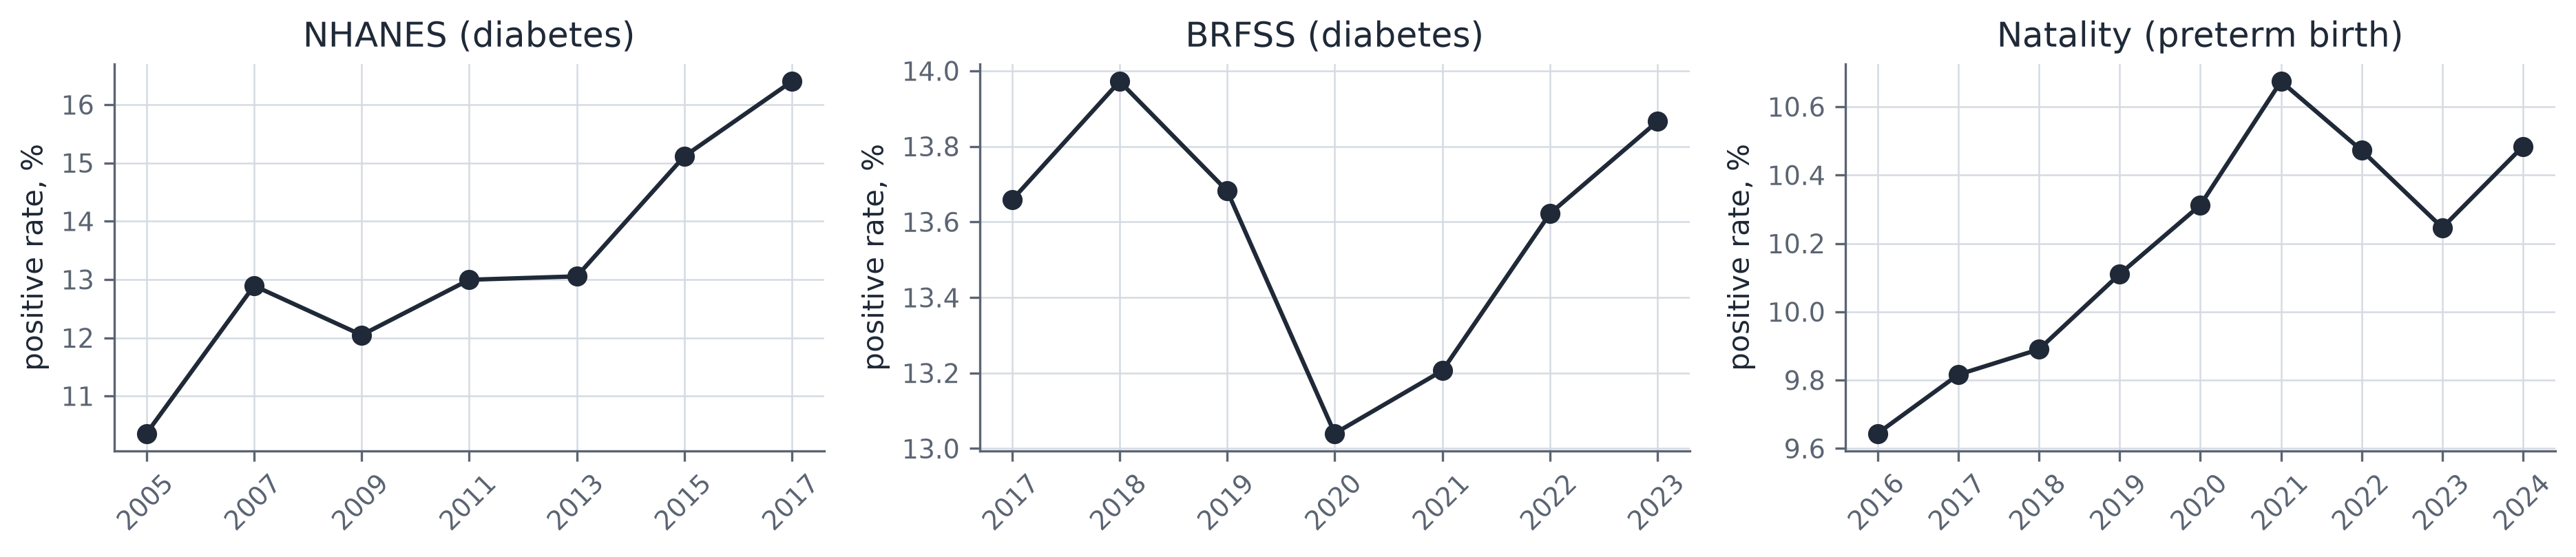

Positive-class rate per period (label shift). NHANES cycles are labelled by start year.


In [15]:
# --- from scripts/make_figures.py ---
def fig_prevalence():
    dss = present("drift_periods.csv")
    fig, axes = panels(len(dss), 2.8)
    for ax, ds in zip(axes, dss):
        p = pd.read_csv(res(ds, "drift_periods.csv"))
        ax.plot(range(len(p)), p["prevalence"] * 100, marker="o", color=INK)
        ax.set_xticks(range(len(p)), [str(c)[:4] for c in p["cycle"]], rotation=45)
        ax.set_title(NAMES[ds]); ax.set_ylabel("positive rate, %")
    fig.tight_layout()
    save(fig, "fig01_prevalence", "Positive-class rate per period (label shift). NHANES cycles are labelled by start year.")


fig_prevalence()
show("fig01_prevalence")

**Label shift.** Diagnosed diabetes rises steadily in NHANES (10.4% -> 16.4%). BRFSS is flat with a
dip in the COVID-19 year 2020. The preterm-birth rate rises to a 2021 peak.

### 5.2 Missing values and feature types

In [16]:
rows = []
for ds, (data, numeric, categorical) in DATA.items():
    miss = data[numeric + categorical].isna().mean()
    rows.append({"dataset": ds, "numeric": len(numeric), "categorical": len(categorical),
                 "mean missing share": miss.mean(), "features > 50% missing": int((miss > 0.5).sum()),
                 "features without missing": int((miss == 0).sum())})
display(pd.DataFrame(rows).round(3))
for ds, (data, numeric, categorical) in DATA.items():
    print(ds, "- numeric features, summary:")
    display(data[numeric].describe().T.head(8).round(2))

,dataset,numeric,categorical,mean missing share,features > 50% missing,features without missing
0,nhanes,102,178,0.298,97,29
1,brfss,19,74,0.179,17,4
2,natality,16,57,0.047,1,16


nhanes - numeric features, summary:


,count,mean,std,min,25%,50%,75%,max
ALQ130,22481.0,2.81,2.73,1.00,1.0,2.0,3.0,83.00
BMXARMC,35451.0,33.07,5.17,16.80,29.5,32.6,36.1,62.40
BMXARML,35451.0,37.26,2.83,24.50,35.2,37.2,39.2,49.90
BMXBMI,36735.0,29.11,6.95,13.18,24.3,28.0,32.5,130.21
BMXHT,36804.0,166.97,10.16,123.30,159.5,166.7,174.3,204.50
BMXLEG,34957.0,38.61,3.93,20.40,36.0,38.6,41.2,55.50
BMXWAIST,35052.0,99.11,16.31,55.50,87.5,97.8,108.7,178.20
BMXWT,36806.0,81.40,21.61,29.10,66.3,78.3,92.6,371.00


brfss - numeric features, summary:


,count,mean,std,min,25%,50%,75%,max
HHADULTS,342269.0,2.03,1.04,0.0,1.0,2.0,2.0,53.0
PHYSHLTH,342092.0,4.22,8.72,0.0,0.0,0.0,3.0,30.0
MENTHLTH,343584.0,3.97,8.12,0.0,0.0,0.0,3.0,30.0
POORHLTH,185272.0,5.30,9.18,0.0,0.0,0.0,5.0,30.0
CHILDREN,343109.0,0.50,1.08,0.0,0.0,0.0,1.0,83.0
ALCDAY,326447.0,5.00,8.33,0.0,0.0,1.0,5.0,30.0
AVEDRNK,165949.0,2.25,2.55,0.0,1.0,2.0,3.0,88.0
DRNK3GE5,165670.0,1.22,3.99,0.0,0.0,0.0,1.0,76.0


natality - numeric features, summary:


,count,mean,std,min,25%,50%,75%,max
MAGER,450000.0,29.22,5.81,12.0,25.0,29.0,33.0,50.0
FAGECOMB,399317.0,31.90,6.79,9.0,27.0,32.0,36.0,88.0
PRIORLIVE,449296.0,1.13,1.31,0.0,0.0,1.0,2.0,17.0
PRIORDEAD,448822.0,0.02,0.18,0.0,0.0,0.0,0.0,12.0
PRIORTERM,448595.0,0.43,0.90,0.0,0.0,0.0,1.0,25.0
ILLB_R,263584.0,49.43,38.29,3.0,24.0,37.0,63.0,300.0
ILOP_R,83385.0,46.53,45.58,3.0,14.0,30.0,62.0,300.0
ILP_R,259246.0,42.70,35.86,3.0,19.0,31.0,54.0,300.0


## 6. Train/test splitting

We use TabReD's split construction (from its preprocessing scripts):
* **default** time split: train on the early periods, validate on the next period, test on the
  latest periods;
* **sliding-window-k** (k = 0, 1, 2): train on 3 consecutive periods, validate on the next one, test
  on the one after;
* **random-k**: the rows of sliding-window-k pooled, shuffled and re-split into the **same sizes**
  (the classic random split; the only difference from sliding-window-k is the time order).

The validation split is used for hyperparameter selection, the MLP's early stopping and the decision
threshold. The test split is scored once. A check asserts that no row appears in two parts of a split.

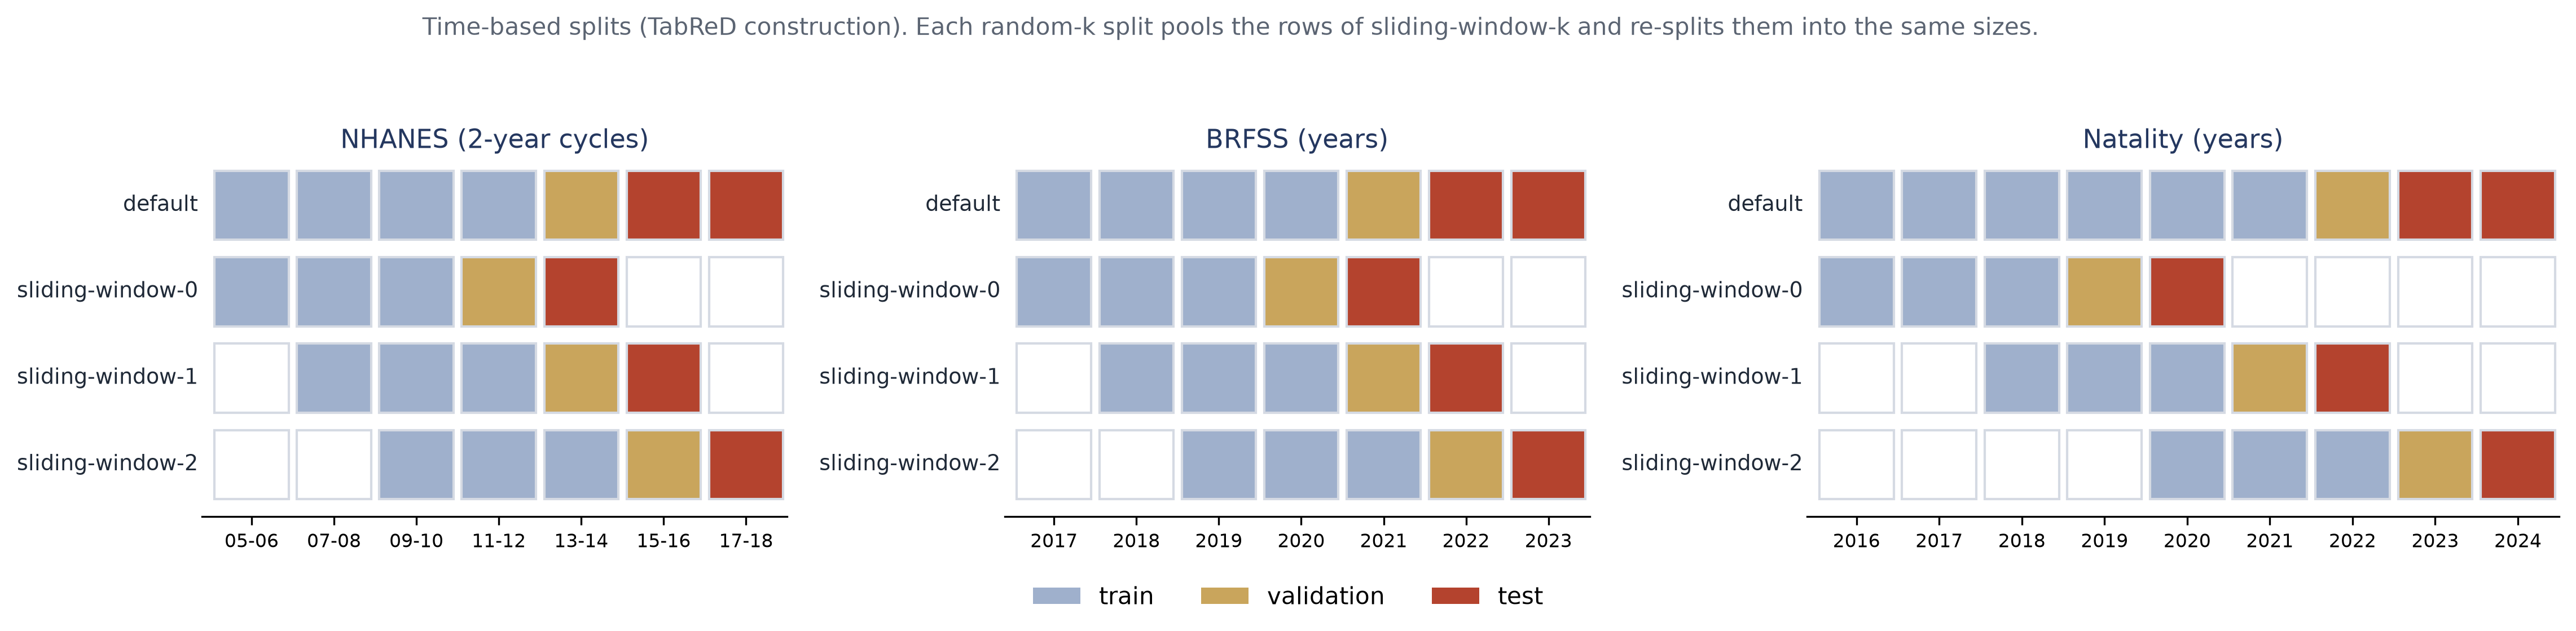

In [17]:
display(Image(filename=str(ROOT / "figures" / "d03_splits.png"), width=1000))

In [18]:
# --- from scripts/run_benchmark.py ---
def make_splits(data: pd.DataFrame, seed: int, spec: dict = DATASETS["nhanes"]) -> dict[str, dict[str, pd.DataFrame]]:
    periods, (n_tr, n_va) = spec["periods"], spec["default"]
    by = {c: data[data["cycle"] == c] for c in periods}
    cat = lambda cs: pd.concat([by[c] for c in cs], ignore_index=True)  # noqa: E731
    splits = {"default": {"train": cat(periods[:n_tr]), "val": cat(periods[n_tr:n_tr + n_va]),
                          "test": cat(periods[n_tr + n_va:])}}
    for k, s in enumerate(spec["windows"]):
        window = {"train": cat(periods[s:s + 3]), "val": cat([periods[s + 3]]), "test": cat([periods[s + 4]])}
        splits[f"sliding-window-{k}"] = window
        # TabReD: random splits shuffle all rows of the window and re-split into the same sizes.
        pooled = pd.concat(window.values(), ignore_index=True)
        order = np.random.default_rng(seed + k).permutation(len(pooled))
        n_tr, n_va = len(window["train"]), len(window["val"])
        splits[f"random-{k}"] = {"train": pooled.iloc[order[:n_tr]].reset_index(drop=True),
                                 "val": pooled.iloc[order[n_tr:n_tr + n_va]].reset_index(drop=True),
                                 "test": pooled.iloc[order[n_tr + n_va:]].reset_index(drop=True)}
    for name, parts in splits.items():
        ids = [set(p["SEQN"]) for p in parts.values()]
        assert not (ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2]), f"{name}: splits overlap"
    return splits


def describe(splits) -> pd.DataFrame:
    rows = []
    for name, parts in splits.items():
        for part, df in parts.items():
            rows.append({"split": name, "part": part, "n": len(df), "n_pos": int(df["label"].sum()),
                         "prevalence": df["label"].mean(),
                         "cycles": ",".join(sorted(df["cycle"].unique()))})
    return pd.DataFrame(rows)

In [19]:
SPLITS_BY_DS = {ds: make_splits(DATA[ds][0], CONFIG["seed"], DATASETS[ds]) for ds in DATASETS}
for ds, splits in SPLITS_BY_DS.items():
    t = describe(splits)
    t.to_csv(SUMMARY_DIR / f"splits_{ds}.csv", index=False)
    print(ds); display(t.pivot_table(index="split", columns="part", values="n", sort=False)
                       .join(t[t["part"] == "test"].set_index("split")[["prevalence", "cycles"]]
                             .rename(columns={"prevalence": "test prevalence", "cycles": "test periods"})))

nhanes


,train,val,test,test prevalence,test periods
split,,,,,
default,21427.0,5416.0,10444.0,0.157411,"2015-2016,2017-2018"
sliding-window-0,16225.0,5202.0,5416.0,0.130539,2013-2014
random-0,16225.0,5202.0,5416.0,0.116876,"2005-2006,2007-2008,2009-2010,2011-2012,2013-2014"
sliding-window-1,16745.0,5416.0,5346.0,0.151141,2015-2016
random-1,16745.0,5416.0,5346.0,0.130939,"2007-2008,2009-2010,2011-2012,2013-2014,2015-2016"
sliding-window-2,16553.0,5346.0,5098.0,0.163986,2017-2018
random-2,16553.0,5346.0,5098.0,0.139663,"2009-2010,2011-2012,2013-2014,2015-2016,2017-2018"


brfss


,train,val,test,test prevalence,test periods
split,,,,,
default,200000.0,50000.0,100000.0,0.13744,"2022,2023"
sliding-window-0,150000.0,50000.0,50000.0,0.13206,2021
random-0,150000.0,50000.0,50000.0,0.13576,"2017,2018,2019,2020,2021"
sliding-window-1,150000.0,50000.0,50000.0,0.13622,2022
random-1,150000.0,50000.0,50000.0,0.13470,"2018,2019,2020,2021,2022"
sliding-window-2,150000.0,50000.0,50000.0,0.13866,2023
random-2,150000.0,50000.0,50000.0,0.13506,"2019,2020,2021,2022,2023"


natality


,train,val,test,test prevalence,test periods
split,,,,,
default,300000.0,50000.0,100000.0,0.10365,"2023,2024"
sliding-window-0,150000.0,50000.0,50000.0,0.10312,2020
random-0,150000.0,50000.0,50000.0,0.10006,"2016,2017,2018,2019,2020"
sliding-window-1,150000.0,50000.0,50000.0,0.10472,2022
random-1,150000.0,50000.0,50000.0,0.10364,"2018,2019,2020,2021,2022"
sliding-window-2,150000.0,50000.0,50000.0,0.10484,2024
random-2,150000.0,50000.0,50000.0,0.10426,"2020,2021,2022,2023,2024"


## 7. Cross-validation

**Strategy:** 5-fold *stratified* cross-validation (each fold keeps the positive rate) on the
**development periods of the default split** (train + validation periods). The test periods are
never part of cross-validation. Each model uses the hyperparameters selected on validation in the
main run; the MLP trains for the epoch at which early stopping stopped in the main run (no
validation set exists inside a fold); threshold-based metrics use 0.5.

CV answers a different question than the time split: it measures **in-period** (i.i.d.) performance
and its stability across folds, while the time split measures transfer to later periods. Comparing
the two is part of the results. CV is executed in Section 8.3, after the hyperparameters are
selected.

## 8. Model training

Five models share the preprocessing pipeline:
1. **Logistic Regression** (`class_weight="balanced"`), grid over `C`;
2. **Random Forest** (300 trees, `class_weight="balanced_subsample"`), grid over depth and leaf size;
3. **XGBoost** (`tree_method="hist"`, `scale_pos_weight = n_neg / n_pos`), grid over learning rate and depth;
4. **LightGBM** (`scale_pos_weight`, deterministic mode), grid over learning rate and leaves;
5. **MLP** (scikit-learn `MLPClassifier`, one or two hidden layers), trained one epoch at a time
   with balanced sample weights and early stopping on validation loss (patience 10, max 200 epochs);
   the weights of the best epoch are kept.

Class imbalance (10-16% positives) is handled with balanced weights in every model.

In [20]:
# --- from src/clinical_tabred/models.py ---
def expand_grid(grid: dict) -> list[dict]:
    """Turn {"a": [1, 2], "b": [3]} into [{"a": 1, "b": 3}, {"a": 2, "b": 3}]."""
    keys = list(grid)
    return [dict(zip(keys, values)) for values in itertools.product(*grid.values())]


def make_estimator(name: str, params: dict, y_train: pd.Series, seed: int, n_jobs: int,
                   balanced: bool = True):
    """Create one (unfitted) classifier.

    `balanced=True` turns on class-imbalance handling: only ~13% of respondents are
    positive, so without it the models would mostly learn to predict "no diabetes".
    """
    ratio = float((y_train == 0).sum() / (y_train == 1).sum()) if balanced else 1.0
    if name == "logreg":
        return LogisticRegression(C=params["C"], max_iter=2000,
                                  class_weight="balanced" if balanced else None)
    if name == "random_forest":
        return RandomForestClassifier(
            **params, random_state=seed, n_jobs=n_jobs,
            class_weight="balanced_subsample" if balanced else None)
    if name in ("xgboost", "lightgbm") and {"xgboost": XGBClassifier,
                                            "lightgbm": LGBMClassifier}[name] is None:
        raise ImportError(f"{name} is not installed: run `uv pip install -r requirements.txt`")
    if name == "xgboost":
        return XGBClassifier(**params, tree_method="hist", scale_pos_weight=ratio,
                             eval_metric="logloss", random_state=seed, n_jobs=n_jobs)
    if name == "lightgbm":
        return LGBMClassifier(**params, scale_pos_weight=ratio, random_state=seed,
                              n_jobs=n_jobs, deterministic=True, force_row_wise=True,
                              verbose=-1)
    if name == "mlp":
        return MLPClassifier(hidden_layer_sizes=tuple(params["hidden_layer_sizes"]),
                             alpha=params["alpha"], learning_rate_init=1e-3, batch_size=128,
                             random_state=seed)
    raise ValueError(f"Unknown model name '{name}'. Choose one of {MODEL_NAMES}.")


def epoch_scores(model, X, y, weights) -> tuple[float, float]:
    """Log loss and accuracy (threshold 0.5) of the current MLP on one data split."""
    prob = model.predict_proba(X)[:, 1]
    loss = log_loss(y, prob, sample_weight=weights, labels=[0, 1])
    accuracy = float(np.mean((prob >= 0.5) == y))
    return loss, accuracy


def train_mlp(model: MLPClassifier, X_train, y_train, X_val, y_val, max_epochs: int,
              patience: int, balanced: bool) -> tuple[MLPClassifier, pd.DataFrame, int]:
    """Train the MLP one epoch at a time with early stopping on validation loss.

    Each `partial_fit` call is one pass (epoch) over the training data. sklearn's
    MLP has no `class_weight`, so imbalance is handled with "balanced" sample
    weights; the same weighting is used for the losses we record. If no validation
    data is given, the loop simply runs `max_epochs` epochs.

    Returns (model with the best epoch's weights, per-epoch history, best epoch).
    """
    y_train, y_val = np.asarray(y_train), (None if y_val is None else np.asarray(y_val))
    w_train = compute_sample_weight("balanced", y_train) if balanced else None
    w_val = compute_sample_weight("balanced", y_val) if balanced and y_val is not None else None
    best_model, best_loss, best_epoch, history = model, np.inf, 0, []
    for epoch in range(1, max_epochs + 1):
        model.partial_fit(X_train, y_train, classes=[0, 1], sample_weight=w_train)
        train_loss, train_acc = epoch_scores(model, X_train, y_train, w_train)
        row = {"epoch": epoch, "train_loss": train_loss, "train_accuracy": train_acc}
        if X_val is None:
            history.append(row)
            best_model, best_epoch = model, epoch
            continue
        row["val_loss"], row["val_accuracy"] = epoch_scores(model, X_val, y_val, w_val)
        history.append(row)
        if row["val_loss"] < best_loss - 1e-4:  # a real improvement: remember these weights
            best_loss, best_epoch, best_model = row["val_loss"], epoch, copy.deepcopy(model)
        elif epoch - best_epoch >= patience:  # no improvement for `patience` epochs: stop
            break
    history = pd.DataFrame(history)
    history["best_epoch"] = best_epoch
    return best_model, history, best_epoch


def fit_model(name: str, params: dict, X_train: pd.DataFrame, y_train: pd.Series,
              X_val, y_val, settings: dict) -> dict:
    """Fit preprocessing + model on the training split and return a dict with the fitted
    pipeline, the training time in seconds and (MLP only) the training history.

    `settings` holds numeric/categorical feature lists, seed, n_jobs, balanced,
    max_epochs and patience.
    """
    start = time.perf_counter()
    preprocessor = make_preprocessor(settings["numeric"], settings["categorical"])
    estimator = make_estimator(name, params, y_train, settings["seed"], settings["n_jobs"],
                               settings["balanced"])
    history, best_epoch = None, None
    if name == "mlp":
        Xt_train = preprocessor.fit_transform(X_train)
        Xt_val = None if X_val is None else preprocessor.transform(X_val)
        estimator, history, best_epoch = train_mlp(
            estimator, Xt_train, y_train, Xt_val, y_val, settings["max_epochs"],
            settings["patience"], settings["balanced"])
        pipeline = Pipeline([("prep", preprocessor), ("model", estimator)])
    else:
        pipeline = Pipeline([("prep", preprocessor), ("model", estimator)])
        pipeline.fit(X_train, y_train)
    return {"pipeline": pipeline, "train_time_s": time.perf_counter() - start,
            "history": history, "best_epoch": best_epoch}


def predict_proba(pipeline: Pipeline, X: pd.DataFrame) -> tuple[np.ndarray, float]:
    """Positive-class probabilities and inference time in milliseconds per 1,000 rows."""
    start = time.perf_counter()
    prob = pipeline.predict_proba(X)[:, 1]
    ms_per_1k = (time.perf_counter() - start) * 1000 / max(len(X), 1) * 1000
    return prob, ms_per_1k

### 8.1 Metrics and threshold (used by the evaluation of every fitted model)
The decision threshold is the one that maximises F1 on the **validation** split; metrics are also
reported at 0.5.

In [21]:
# --- from src/clinical_tabred/evaluation.py ---
def safe_ratio(numerator: float, denominator: float, name: str) -> float:
    """Divide, but return NaN (and log a warning) instead of crashing or writing 0."""
    if denominator == 0:
        logger.warning("%s is undefined (division by zero); stored as NaN", name)
        return float("nan")
    return numerator / denominator


def ranking_metrics(y: np.ndarray, prob: np.ndarray) -> dict:
    """ROC-AUC and PR-AUC (average precision). Both need both classes to be present."""
    if len(np.unique(y)) < 2:
        logger.warning("Only one class present: ROC-AUC and PR-AUC stored as NaN")
        return {"roc_auc": float("nan"), "pr_auc": float("nan")}
    return {"roc_auc": roc_auc_score(y, prob), "pr_auc": average_precision_score(y, prob)}


def compute_metrics(y, prob, threshold: float) -> dict:
    """All metrics for one set of predictions.

    Probabilities >= threshold are called positive. Returns accuracy, precision,
    recall, F1, ROC-AUC, PR-AUC, Brier score and the confusion-matrix counts.
    """
    y, prob = np.asarray(y).astype(int), np.asarray(prob, dtype=float)
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    precision = safe_ratio(tp, tp + fp, "precision")
    recall = safe_ratio(tp, tp + fn, "recall")
    f1 = safe_ratio(2 * tp, 2 * tp + fp + fn, "f1")
    return {"accuracy": (tp + tn) / len(y), "precision": precision, "recall": recall,
            "f1": f1, **ranking_metrics(y, prob), "brier": brier_score_loss(y, prob),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
            "threshold": threshold, "n": len(y), "n_pos": int(y.sum())}


def best_f1_threshold(y_val, prob_val) -> float:
    """Return the probability threshold that maximises F1 on the validation set.

    The threshold is chosen on validation data only; using the test set here would
    make the reported test scores optimistic.
    """
    precision, recall, thresholds = precision_recall_curve(y_val, prob_val)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[np.argmax(f1[:-1])])  # the last P/R pair has no threshold

### 8.2 Tuning on validation and evaluation of one split
Every configuration of a model's grid is trained on the training split and scored on validation;
the best by validation PR-AUC (ROC-AUC breaks ties) is kept. PR-AUC is the selection metric because
positives are rare. The kept model is then scored on every part of the split.

In [22]:
# --- from src/clinical_tabred/experiment.py ---
def fit_on_splits(name: str, params: dict, splits: dict, settings: dict) -> dict:
    """Fit one model on splits["train"], using splits["val"] for MLP early stopping."""
    features = settings["numeric"] + settings["categorical"]
    return fit_model(name, params, feature_matrix(splits["train"], features),
                     splits["train"]["label"].astype(int),
                     feature_matrix(splits["val"], features), splits["val"]["label"].astype(int),
                     settings)


def validation_scores(fitted: dict, val: pd.DataFrame, settings: dict) -> tuple:
    """Validation PR-AUC and ROC-AUC of a fitted model (used for model selection)."""
    prob, _ = predict_proba(fitted["pipeline"],
                            feature_matrix(val, settings["numeric"] + settings["categorical"]))
    y = val["label"].astype(int)
    return average_precision_score(y, prob), roc_auc_score(y, prob)


def tune_model(name: str, grid: dict, splits: dict, settings: dict, tag: dict):
    """Try every configuration in the grid and keep the best by validation PR-AUC.

    ROC-AUC breaks ties. Returns (best fitted model, best params, one row per config).
    """
    rows, best = [], None
    for params in expand_grid(grid):
        fitted = fit_on_splits(name, params, splits, settings)
        pr_auc, roc_auc = validation_scores(fitted, splits["val"], settings)
        rows.append({**tag, "model": name, "params": json.dumps(params), "val_pr_auc": pr_auc,
                     "val_roc_auc": roc_auc, "train_time_s": fitted["train_time_s"]})
        if best is None or (pr_auc, roc_auc) > best[0]:
            best = ((pr_auc, roc_auc), fitted, params)
    for row in rows:
        row["selected"] = row["params"] == json.dumps(best[2])
    return best[1], best[2], rows


def evaluate_model(name: str, fitted: dict, splits: dict, settings: dict, tag: dict):
    """Score a fitted model on every split at threshold 0.5 and at the tuned threshold.

    The tuned threshold maximises F1 on the validation split. Returns
    (metric rows, prediction table for the test splits, chosen threshold).
    """
    features = settings["numeric"] + settings["categorical"]
    probs, timings = {}, {}
    for split_name, part in splits.items():
        probs[split_name], timings[split_name] = predict_proba(
            fitted["pipeline"], feature_matrix(part, features))
    threshold = best_f1_threshold(splits["val"]["label"].astype(int), probs["val"])
    rows, predictions = [], []
    for split_name, part in splits.items():
        for rule, value in [("0.5", 0.5), ("val_f1", threshold)]:
            metrics = compute_metrics(part["label"].astype(int), probs[split_name], value)
            rows.append({**tag, "model": name, "split": split_name, "threshold_rule": rule,
                         **metrics, "train_time_s": fitted["train_time_s"],
                         "infer_ms_per_1k": timings[split_name]})
        if split_name.startswith("test"):
            predictions.append(pd.DataFrame({
                **tag, "model": name, "split": split_name, "SEQN": part["SEQN"].to_numpy(),
                "cycle": part["cycle"].to_numpy(), "label": part["label"].astype(int).to_numpy(),
                "probability": probs[split_name]}))
    return rows, pd.concat(predictions, ignore_index=True), threshold

The full benchmark for one dataset: every model on every split (5 models x 7 splits), followed by
`summarize`, which computes the bootstrap CIs and the random-vs-time comparison (Section 9). The
bootstrap functions it uses:

In [23]:
# --- from src/clinical_tabred/evaluation.py ---
def bootstrap_indices(n: int, n_resamples: int, seed: int) -> np.ndarray:
    """Matrix of resampled row indices (one row per bootstrap resample)."""
    return np.random.default_rng(seed).integers(0, n, size=(n_resamples, n))


def bootstrap_metric(y, prob, metric, indices: np.ndarray) -> np.ndarray:
    """Value of `metric(y, prob)` on every bootstrap resample (NaN if one class is missing)."""
    y, prob = np.asarray(y), np.asarray(prob)
    values = np.full(len(indices), np.nan)
    for i, idx in enumerate(indices):
        if y[idx].min() != y[idx].max():
            values[i] = metric(y[idx], prob[idx])
    return values


def percentile_ci(values: np.ndarray, confidence: float) -> tuple[float, float]:
    """Percentile confidence interval, e.g. the 2.5th and 97.5th percentiles for 95%."""
    alpha = (1 - confidence) / 2
    return float(np.nanquantile(values, alpha)), float(np.nanquantile(values, 1 - alpha))


def metric_ci(y, prob, n_resamples: int, confidence: float, seed: int) -> dict:
    """Point estimates and bootstrap CIs for ROC-AUC and PR-AUC on one test set."""
    indices = bootstrap_indices(len(y), n_resamples, seed)
    result = {}
    for name, metric in [("roc_auc", roc_auc_score), ("pr_auc", average_precision_score)]:
        low, high = percentile_ci(bootstrap_metric(y, prob, metric, indices), confidence)
        result.update({name: metric(y, prob), f"{name}_low": low, f"{name}_high": high})
    return result


def paired_difference(y, prob_a, prob_b, metric, n_resamples: int, confidence: float,
                      seed: int) -> dict:
    """Paired bootstrap of metric(A) - metric(B) on the SAME test set.

    Both models are scored on identical resamples, so the CI reflects only the
    difference between models. If the CI contains 0 the difference is inconclusive.
    """
    indices = bootstrap_indices(len(y), n_resamples, seed)
    diffs = (bootstrap_metric(y, prob_a, metric, indices)
             - bootstrap_metric(y, prob_b, metric, indices))
    low, high = percentile_ci(diffs, confidence)
    return {"diff": metric(y, prob_a) - metric(y, prob_b), "diff_low": low, "diff_high": high}


def unpaired_difference(y_a, prob_a, y_b, prob_b, metric, n_resamples: int,
                        confidence: float, seed: int) -> dict:
    """Bootstrap of metric(set A) - metric(set B) for two DIFFERENT test sets.

    Each set is resampled independently (used e.g. for in-period vs future test).
    """
    values_a = bootstrap_metric(y_a, prob_a, metric, bootstrap_indices(len(y_a), n_resamples, seed))
    values_b = bootstrap_metric(y_b, prob_b, metric,
                                bootstrap_indices(len(y_b), n_resamples, seed + 1))
    low, high = percentile_ci(values_a - values_b, confidence)
    return {"diff": metric(y_a, prob_a) - metric(y_b, prob_b), "diff_low": low, "diff_high": high}


def paired_comparisons(test: pd.DataFrame, reference: str, n_resamples: int,
                       confidence: float, seed: int) -> pd.DataFrame:
    """Paired bootstrap: the reference model minus every other model on one test set."""
    wide = test.pivot(index="SEQN", columns="model", values="probability")
    y = test.drop_duplicates("SEQN").set_index("SEQN").loc[wide.index, "label"].to_numpy()
    rows = []
    for other in [m for m in wide.columns if m != reference]:
        for name, metric in [("roc_auc", roc_auc_score), ("pr_auc", average_precision_score)]:
            result = paired_difference(y, wide[reference].to_numpy(), wide[other].to_numpy(),
                                       metric, n_resamples, confidence, seed)
            conclusive = result["diff_low"] > 0 or result["diff_high"] < 0
            rows.append({"reference": reference, "other": other, "metric": name, **result,
                         "ci_excludes_zero": conclusive})
    return pd.DataFrame(rows)

In [24]:
# --- from scripts/run_benchmark.py ---
def run_benchmark(dataset: str, models=MODEL_NAMES, only_splits=None, quick: bool = False,
                  n_jobs: int = -1) -> Path:
    """Tune, fit and evaluate every model on every split of one dataset; write all result files."""
    config = load_config()
    seed = config["seed"]
    spec = DATASETS[dataset]
    out_dir = ROOT / (spec["out"] + ("_quick" if quick else ""))
    (out_dir / "predictions").mkdir(parents=True, exist_ok=True)

    data, numeric, categorical = load_dataset(dataset)
    if quick:
        data = data.groupby("cycle").sample(n=600, random_state=seed).reset_index(drop=True)
    settings = model_settings(config, numeric, categorical, n_jobs, quick)
    logger.info("%s: rows %d | numeric %d | categorical %d | models %s", dataset, len(data), len(numeric),
                len(categorical), models)
    pd.DataFrame({"feature": numeric + categorical,
                  "type": ["numeric"] * len(numeric) + ["categorical"] * len(categorical)}
                 ).to_csv(out_dir / "feature_types.csv", index=False)

    splits = make_splits(data, seed, spec)
    if only_splits:
        splits = {k: v for k, v in splits.items() if k in only_splits}
    describe(splits).to_csv(out_dir / "splits.csv", index=False)

    metrics, tuning, preds, history, selected = [], [], [], [], {}
    started = time.perf_counter()
    for split_name, parts in splits.items():
        for model in models:
            t0 = time.perf_counter()
            tag = {"protocol": split_name, "seed": seed}
            fitted, params, rows = tune_model(model, config["models"][model], parts, settings, tag)
            m, p, threshold = evaluate_model(model, fitted, parts, settings, tag)
            metrics += m
            tuning += rows
            preds.append(p)
            selected.setdefault(split_name, {})[model] = {"params": params, "threshold": threshold,
                                                          "best_epoch": fitted["best_epoch"]}
            if fitted["history"] is not None:
                history.append(fitted["history"].assign(protocol=split_name))
            test_auc = next(r for r in m if r["split"] == "test" and r["threshold_rule"] == "val_f1")["roc_auc"]
            logger.info("%-17s %-14s test ROC-AUC %.3f  (%.0fs, total %.0fs)", split_name, model,
                        test_auc, time.perf_counter() - t0, time.perf_counter() - started)
        # Save after every split so a long run can be inspected (or resumed) early.
        pd.DataFrame(metrics).to_csv(out_dir / "metrics.csv", index=False)
        pd.DataFrame(tuning).to_csv(out_dir / "tuning.csv", index=False)
        pd.concat(preds, ignore_index=True).to_csv(out_dir / "predictions" / "test_predictions.csv", index=False)
        (out_dir / "selected_models.json").write_text(json.dumps(selected, indent=2))
        if history:
            pd.concat(history, ignore_index=True).to_csv(out_dir / "mlp_history.csv", index=False)

    summarize(pd.DataFrame(metrics), pd.concat(preds, ignore_index=True), config, out_dir, models,
              n_windows=len(spec["windows"]))
    logger.info("Done in %.1f min. Results in %s", (time.perf_counter() - started) / 60, out_dir)
    return out_dir


def summarize(metrics: pd.DataFrame, preds: pd.DataFrame, config: dict, out_dir: Path, models, n_windows=3):
    """Tables that answer the TabReD questions."""
    boot = config["bootstrap"]
    n_res, conf, seed = boot["n_resamples"], boot["confidence"], config["seed"]
    test = metrics[(metrics["split"] == "test") & (metrics["threshold_rule"] == "val_f1")]

    # 1) Test ROC-AUC / PR-AUC per split and model (wide view).
    table = test.pivot_table(index="model", columns="protocol", values="roc_auc").reindex(models)
    table.round(4).to_csv(out_dir / "test_roc_auc_by_split.csv")

    # 2) Time-based vs random split, per window and averaged (TabReD Table 4 idea).
    rows = []
    for k in range(n_windows):
        tw, rw = f"sliding-window-{k}", f"random-{k}"
        if tw not in set(preds["protocol"]) or rw not in set(preds["protocol"]):
            continue
        for model in models:
            a = preds[(preds["protocol"] == rw) & (preds["model"] == model)]
            b = preds[(preds["protocol"] == tw) & (preds["model"] == model)]
            if a.empty or b.empty:
                continue
            for name, metric in [("roc_auc", roc_auc_score), ("pr_auc", average_precision_score)]:
                r = unpaired_difference(a["label"].to_numpy(), a["probability"].to_numpy(),
                                        b["label"].to_numpy(), b["probability"].to_numpy(),
                                        metric, n_res, conf, seed)
                rows.append({"window": k, "model": model, "metric": name,
                             "random": metric(a["label"], a["probability"]),
                             "time": metric(b["label"], b["probability"]), **r,
                             "ci_excludes_zero": r["diff_low"] > 0 or r["diff_high"] < 0})
    gaps = pd.DataFrame(rows)
    if not gaps.empty:
        gaps.to_csv(out_dir / "random_minus_time_by_window.csv", index=False)
        mean = gaps.groupby(["model", "metric"])[["random", "time", "diff"]].mean().reset_index()
        mean.to_csv(out_dir / "random_minus_time_mean.csv", index=False)
        # 3) Model ranking under time vs random splits (does the ranking change?).
        roc = mean[mean["metric"] == "roc_auc"].set_index("model")
        ranks = pd.DataFrame({"mean_roc_auc_time": roc["time"], "rank_time": roc["time"].rank(ascending=False),
                              "mean_roc_auc_random": roc["random"],
                              "rank_random": roc["random"].rank(ascending=False)})
        ranks.sort_values("rank_time").to_csv(out_dir / "ranking_time_vs_random.csv")

    # 4) Default split: bootstrap CIs and paired comparisons against the validation-selected model.
    default = preds[preds["protocol"] == "default"]
    if not default.empty:
        cis = [{"model": m, **metric_ci(g["label"].to_numpy(), g["probability"].to_numpy(), n_res, conf, seed)}
               for m, g in default.groupby("model")]
        pd.DataFrame(cis).to_csv(out_dir / "default_test_ci.csv", index=False)
        val = metrics[(metrics["protocol"] == "default") & (metrics["split"] == "val")
                      & (metrics["threshold_rule"] == "val_f1")]
        best = val.sort_values(["pr_auc", "roc_auc"], ascending=False)["model"].iloc[0]
        if default["model"].nunique() > 1:
            paired_comparisons(default, best, n_res, conf, seed).to_csv(
                out_dir / "default_paired_comparisons.csv", index=False)
        (out_dir / "default_selected_model.txt").write_text(best + "\n")

In [25]:
if RUN_EXPERIMENTS:
    for ds in DATASETS:                      # one at a time: the models use all CPU cores
        run_benchmark(ds)
else:
    print("RUN_EXPERIMENTS = False: using the saved results in", ", ".join(DATASETS[ds]["out"] for ds in DATASETS))
for ds in DATASETS:
    out = ROOT / DATASETS[ds]["out"]
    print(f"{ds:9s}", sorted(p.name for p in out.glob("*.csv"))[:6], "...")

RUN_EXPERIMENTS = False: using the saved results in results_nhanes, results_brfss, results_natality
nhanes    ['cv_folds.csv', 'cv_summary.csv', 'default_paired_comparisons.csv', 'default_test_ci.csv', 'drift_domain.csv', 'drift_events.csv'] ...
brfss     ['cv_folds.csv', 'cv_summary.csv', 'default_paired_comparisons.csv', 'default_test_ci.csv', 'drift_domain.csv', 'drift_events.csv'] ...
natality  ['cv_folds.csv', 'cv_summary.csv', 'default_paired_comparisons.csv', 'default_test_ci.csv', 'drift_domain.csv', 'drift_events.csv'] ...


**Reproduction check.** For every dataset, the configuration selected on validation for each model
(saved in `selected_models.json`) is trained again on the default split, here in the notebook, and
its test ROC-AUC and threshold are compared with the saved benchmark results.

In [26]:
def reproduce_default_split(ds: str) -> pd.DataFrame:
    data, numeric, categorical = DATA[ds]
    parts = SPLITS_BY_DS[ds]["default"]
    settings = model_settings(CONFIG, numeric, categorical)
    out = ROOT / DATASETS[ds]["out"]
    selected = json.loads((out / "selected_models.json").read_text())["default"]
    saved = pd.read_csv(out / "metrics.csv")
    saved = saved[(saved["protocol"] == "default") & (saved["split"] == "test")
                  & (saved["threshold_rule"] == "val_f1")].set_index("model")
    rows = []
    for model in MODEL_NAMES:
        fitted = fit_on_splits(model, selected[model]["params"], parts, settings)
        metrics, _, threshold = evaluate_model(model, fitted, parts, settings, {"protocol": "default"})
        test = next(m for m in metrics if m["split"] == "test" and m["threshold_rule"] == "val_f1")
        rows.append({"dataset": ds, "model": model, "params": json.dumps(selected[model]["params"]),
                     "test_roc_auc_now": test["roc_auc"], "test_roc_auc_saved": saved.loc[model, "roc_auc"],
                     "threshold_now": threshold, "threshold_saved": selected[model]["threshold"],
                     "train_time_s": round(fitted["train_time_s"], 1)})
        print(f"{ds:9s} {model:14s} ROC-AUC now {test['roc_auc']:.4f} | saved {saved.loc[model, 'roc_auc']:.4f}")
    return pd.DataFrame(rows)


start = time.perf_counter()
repro = pd.concat([reproduce_default_split(ds) for ds in DATASETS], ignore_index=True)
repro["abs_diff"] = (repro["test_roc_auc_now"] - repro["test_roc_auc_saved"]).abs()
repro.to_csv(SUMMARY_DIR / "reproduction_check.csv", index=False)
print(f"finished in {(time.perf_counter() - start) / 60:.1f} min; largest |difference| {repro['abs_diff'].max():.2e}")
display(repro.round(4))

nhanes    logreg         ROC-AUC now 0.8818 | saved 0.8818


nhanes    random_forest  ROC-AUC now 0.8758 | saved 0.8758


nhanes    xgboost        ROC-AUC now 0.9008 | saved 0.9004


nhanes    lightgbm       ROC-AUC now 0.8993 | saved 0.8993


nhanes    mlp            ROC-AUC now 0.8867 | saved 0.8867


brfss     logreg         ROC-AUC now 0.8219 | saved 0.8219


... (6 outputs left out)

natality  xgboost        ROC-AUC now 0.7504 | saved 0.7504


natality  lightgbm       ROC-AUC now 0.7503 | saved 0.7503


natality  mlp            ROC-AUC now 0.7455 | saved 0.7455
finished in 2.8 min; largest |difference| 4.17e-04


,dataset,model,params,test_roc_auc_now,test_roc_auc_saved,threshold_now,threshold_saved,train_time_s,abs_diff
0,nhanes,logreg,"{""C"": 0.01}",0.8818,0.8818,0.7136,0.7136,1.7,0.0000
1,nhanes,random_forest,"{""n_estimators"": 300, ""max_depth"": null, ""min_samples_leaf"": 10}",0.8758,0.8758,0.4679,0.4679,1.3,0.0000
2,nhanes,xgboost,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 3, ""subsample"": 0.8}",0.9008,0.9004,0.7124,0.7266,0.9,0.0004
3,nhanes,lightgbm,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""num_leaves"": 7}",0.8993,0.8993,0.7138,0.7138,0.6,0.0000
4,nhanes,mlp,"{""hidden_layer_sizes"": [64, 32], ""alpha"": 0.0001}",0.8867,0.8867,0.7183,0.7183,1.9,0.0000
5,brfss,logreg,"{""C"": 1.0}",0.8219,0.8219,0.6411,0.6411,6.0,0.0000
6,brfss,random_forest,"{""n_estimators"": 300, ""max_depth"": null, ""min_samples_leaf"": 10}",0.8215,0.8215,0.5454,0.5454,19.2,0.0000
7,brfss,xgboost,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 5, ""subsample"": 0.8}",0.8240,0.8240,0.6631,0.6631,2.4,0.0000
8,brfss,lightgbm,"{""n_estimators"": 300, ""learning_rate"": 0.03, ""num_leaves"": 31}",0.8258,0.8258,0.6819,0.6819,1.9,0.0000
9,brfss,mlp,"{""hidden_layer_sizes"": [64], ""alpha"": 0.0001}",0.8240,0.8240,0.6886,0.6886,9.3,0.0000


14 of the 15 models reproduce the saved test ROC-AUC and threshold exactly (BRFSS and natality were
benchmarked on this machine). NHANES XGBoost differs in the fourth decimal (0.9008 here vs 0.9004
saved): the NHANES benchmark was run on a different (Windows) computer, and XGBoost's histogram
algorithm is deterministic on one machine but not bit-identical across CPUs. All reported NHANES
numbers are the saved ones.

Tried configurations and the selected one (default split; full tables in `results_<dataset>/tuning.csv`):

In [27]:
for ds in DATASETS:
    t = pd.read_csv(ROOT / DATASETS[ds]["out"] / "tuning.csv")
    t = t[t["protocol"] == "default"][["model", "params", "val_pr_auc", "val_roc_auc", "train_time_s", "selected"]]
    print(ds); display(t.round(4))

nhanes


,model,params,val_pr_auc,val_roc_auc,train_time_s,selected
0,logreg,"{""C"": 0.01}",0.6391,0.9051,2.1268,True
1,logreg,"{""C"": 0.1}",0.6383,0.9033,3.0265,False
2,logreg,"{""C"": 1.0}",0.6338,0.9018,3.6849,False
3,logreg,"{""C"": 10.0}",0.6321,0.9014,3.7813,False
4,random_forest,"{""n_estimators"": 300, ""max_depth"": 6, ""min_samples_leaf"": 1}",0.5106,0.8730,4.5459,False
5,random_forest,"{""n_estimators"": 300, ""max_depth"": 6, ""min_samples_leaf"": 10}",0.5075,0.8711,4.4551,False
6,random_forest,"{""n_estimators"": 300, ""max_depth"": 10, ""min_samples_leaf"": 1}",0.5455,0.8877,6.5173,False
7,random_forest,"{""n_estimators"": 300, ""max_depth"": 10, ""min_samples_leaf"": 10}",0.5487,0.8883,6.8509,False
8,random_forest,"{""n_estimators"": 300, ""max_depth"": null, ""min_samples_leaf"": 1}",0.5563,0.8960,7.8491,False
9,random_forest,"{""n_estimators"": 300, ""max_depth"": null, ""min_samples_leaf"": 10}",0.5606,0.8931,6.4491,True


brfss


,model,params,val_pr_auc,val_roc_auc,train_time_s,selected
0,logreg,"{""C"": 0.01}",0.4027,0.8241,4.0887,False
1,logreg,"{""C"": 0.1}",0.4035,0.8241,5.3749,False
2,logreg,"{""C"": 1.0}",0.4036,0.8241,5.8619,True
3,logreg,"{""C"": 10.0}",0.4035,0.8241,5.4263,False
4,random_forest,"{""n_estimators"": 300, ""max_depth"": 6, ""min_samples_leaf"": 1}",0.3823,0.8103,13.7869,False
5,random_forest,"{""n_estimators"": 300, ""max_depth"": 6, ""min_samples_leaf"": 10}",0.3821,0.8102,13.6828,False
6,random_forest,"{""n_estimators"": 300, ""max_depth"": 10, ""min_samples_leaf"": 1}",0.3937,0.8182,17.1910,False
7,random_forest,"{""n_estimators"": 300, ""max_depth"": 10, ""min_samples_leaf"": 10}",0.3957,0.8185,17.3389,False
8,random_forest,"{""n_estimators"": 300, ""max_depth"": null, ""min_samples_leaf"": 1}",0.3946,0.8198,19.7491,False
9,random_forest,"{""n_estimators"": 300, ""max_depth"": null, ""min_samples_leaf"": 10}",0.4065,0.8238,18.9516,True


natality


,model,params,val_pr_auc,val_roc_auc,train_time_s,selected
0,logreg,"{""C"": 0.01}",0.3676,0.7445,13.5352,False
1,logreg,"{""C"": 0.1}",0.3699,0.7446,24.6659,False
2,logreg,"{""C"": 1.0}",0.3708,0.7445,36.2619,True
3,logreg,"{""C"": 10.0}",0.3706,0.7445,43.4533,False
4,random_forest,"{""n_estimators"": 300, ""max_depth"": 6, ""min_samples_leaf"": 1}",0.3428,0.7288,56.7538,False
5,random_forest,"{""n_estimators"": 300, ""max_depth"": 6, ""min_samples_leaf"": 10}",0.3411,0.7278,55.1424,False
6,random_forest,"{""n_estimators"": 300, ""max_depth"": 10, ""min_samples_leaf"": 1}",0.3469,0.7344,76.9643,False
7,random_forest,"{""n_estimators"": 300, ""max_depth"": 10, ""min_samples_leaf"": 10}",0.3504,0.7350,35.2720,False
8,random_forest,"{""n_estimators"": 300, ""max_depth"": null, ""min_samples_leaf"": 1}",0.3430,0.7314,50.9174,False
9,random_forest,"{""n_estimators"": 300, ""max_depth"": null, ""min_samples_leaf"": 10}",0.3546,0.7434,51.9030,True


### 8.2.1 MLP training curves
The recorded loss curves of the selected MLP configuration on the default split (balanced log loss,
the same weighting as in training). The validation set is a *later period*, so the gap between the
curves includes the temporal shift.

saved fig06_mlp_training_curves


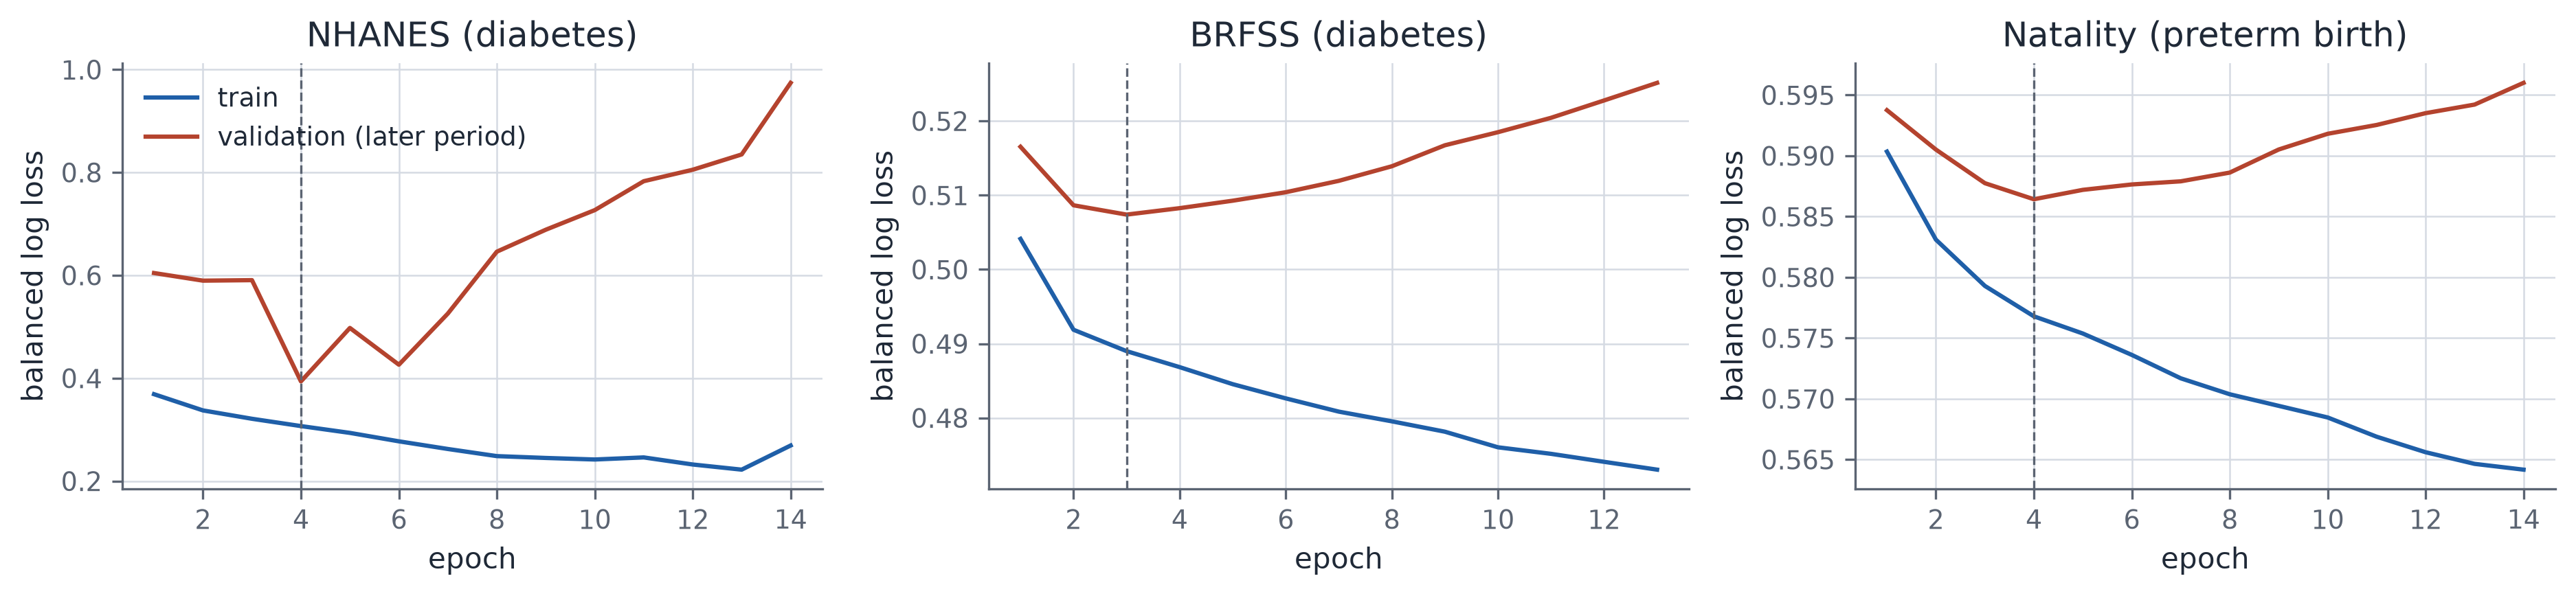

MLP training curves on the default split (selected configuration); dashed line = early-stopping epoch.


In [28]:
# --- from scripts/make_figures.py ---
def fig_mlp():
    dss = present("mlp_history.csv")
    fig, axes = panels(len(dss), 3.0)
    for ax, ds in zip(axes, dss):
        h = pd.read_csv(res(ds, "mlp_history.csv"))
        h = h[h["protocol"] == "default"]
        ax.plot(h["epoch"], h["train_loss"], color=MODEL_COLORS["logreg"], label="train")
        ax.plot(h["epoch"], h["val_loss"], color=MODEL_COLORS["lightgbm"], label="validation (later period)")
        ax.axvline(h["best_epoch"].iloc[0], color=MUTED, ls="--", lw=0.8)
        ax.set_title(NAMES[ds]); ax.set_xlabel("epoch"); ax.set_ylabel("balanced log loss")
    axes[0].legend()
    fig.tight_layout()
    save(fig, "fig06_mlp_training_curves",
         "MLP training curves on the default split (selected configuration); dashed line = early-stopping epoch.")


fig_mlp()
show("fig06_mlp_training_curves")

### 8.3 Cross-validation (strategy in Section 7)

In [29]:
# --- from src/clinical_tabred/experiment.py ---
def cross_validate(protocol: str, dev: pd.DataFrame, params: dict, best_epoch: dict,
                   config: dict, settings: dict) -> list[dict]:
    """Stratified K-fold CV on development data only (the test set is never touched).

    Each model uses the hyperparameters selected for this protocol. The MLP has no
    validation set inside a fold, so it trains for the number of epochs at which
    early stopping halted in the main run. Threshold-based metrics use 0.5.
    """
    folds = StratifiedKFold(n_splits=config["cv"]["n_splits"], shuffle=True,
                            random_state=config["seed"])
    features = settings["numeric"] + settings["categorical"]
    X, y = feature_matrix(dev, features), dev["label"].astype(int)
    rows = []
    for name in MODEL_NAMES:
        fold_settings = {**settings, "max_epochs": best_epoch[name] or settings["max_epochs"]}
        for fold, (train_idx, test_idx) in enumerate(folds.split(X, y), start=1):
            fitted = fit_model(name, params[name], X.iloc[train_idx], y.iloc[train_idx],
                               None, None, fold_settings)
            prob, _ = predict_proba(fitted["pipeline"], X.iloc[test_idx])
            metrics = compute_metrics(y.iloc[test_idx], prob, 0.5)
            rows.append({"protocol": protocol, "model": name, "fold": fold,
                         **{k: metrics[k] for k in ["accuracy", "precision", "recall", "f1",
                                                    "roc_auc", "pr_auc"]}})
    return rows


# --- from scripts/run_cv.py ---
METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]


def run_cv(dataset: str, n_jobs: int = -1) -> pd.DataFrame:
    """5-fold CV of all models on the default split's development periods; writes cv_*.csv."""
    config = load_config()
    spec = DATASETS[dataset]
    out_dir = ROOT / spec["out"]
    selected = json.loads((out_dir / "selected_models.json").read_text())["default"]

    data, numeric, categorical = load_dataset(dataset)
    split = make_splits(data, config["seed"], spec)["default"]
    dev = pd.concat([split["train"], split["val"]], ignore_index=True)
    settings = model_settings(config, numeric, categorical, n_jobs)
    params = {m: v["params"] for m, v in selected.items()}
    best_epoch = {m: v["best_epoch"] for m, v in selected.items()}
    logger.info("%s: 5-fold CV on %d development rows (periods %s)", dataset, len(dev),
                ",".join(sorted(dev["cycle"].unique())))

    rows = cross_validate("default", dev, params, best_epoch, config, settings)
    folds = pd.DataFrame(rows).assign(dataset=dataset)
    folds.to_csv(out_dir / "cv_folds.csv", index=False)
    summary = folds.groupby("model")[METRICS].agg(["mean", "std"])
    summary.columns = [f"{m}_{s}" for m, s in summary.columns]
    summary = summary.reset_index().assign(dataset=dataset)
    summary.to_csv(out_dir / "cv_summary.csv", index=False)
    return summary

In [30]:
# --- from scripts/summarize_benchmarks.py ---
MODELS = ["logreg", "random_forest", "xgboost", "lightgbm", "mlp"]


LABELS = {"logreg": "Logistic Regression", "random_forest": "Random Forest", "xgboost": "XGBoost",
          "lightgbm": "LightGBM", "mlp": "MLP"}


INFO = {
    "nhanes": ("NHANES 2005-2018", "diagnosed diabetes (DIQ010)", "interview + exam + lab"),
    "brfss": ("BRFSS 2017-2023", "diagnosed diabetes (DIABETE3/4)", "telephone survey"),
    "natality": ("Natality 2016-2024", "preterm birth (< 37 weeks)", "birth certificate"),
}


SPLITS = ["default", "sliding-window-0", "sliding-window-1", "sliding-window-2",
          "random-0", "random-1", "random-2"]


def read(ds: str, name: str) -> pd.DataFrame | None:
    path = ROOT / DATASETS[ds]["out"] / name
    return pd.read_csv(path).assign(dataset=ds) if path.exists() else None


def md(df: pd.DataFrame, floatfmt: str = ".3f") -> str:
    return df.to_markdown(index=False, floatfmt=floatfmt)


def cv_tables(present) -> tuple[pd.DataFrame | None, pd.DataFrame | None]:
    """5-fold CV summary (numbers) and a display version with mean +/- std strings."""
    cv = [c for c in (read(ds, "cv_summary.csv") for ds in present) if c is not None]
    if not cv:
        return None, None
    t = pd.concat(cv, ignore_index=True)
    show = t[["dataset", "model"]].copy()
    for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]:
        show[k] = [f"{mu:.3f} ± {sd:.3f}" for mu, sd in zip(t[k + "_mean"], t[k + "_std"])]
    return t, show


if RUN_EXPERIMENTS:
    for ds in DATASETS:
        run_cv(ds)
cv, cv_show = cv_tables(list(DATASETS))
cv.to_csv(SUMMARY_DIR / "cv_summary.csv", index=False)
display(cv_show)

,dataset,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,nhanes,lightgbm,0.846 ± 0.005,0.433 ± 0.009,0.800 ± 0.014,0.562 ± 0.007,0.913 ± 0.005,0.632 ± 0.014
1,nhanes,logreg,0.831 ± 0.007,0.409 ± 0.011,0.835 ± 0.015,0.549 ± 0.010,0.910 ± 0.005,0.612 ± 0.026
2,nhanes,mlp,0.839 ± 0.018,0.423 ± 0.035,0.806 ± 0.045,0.553 ± 0.020,0.908 ± 0.005,0.618 ± 0.018
3,nhanes,random_forest,0.876 ± 0.006,0.498 ± 0.019,0.619 ± 0.019,0.552 ± 0.016,0.893 ± 0.005,0.564 ± 0.017
4,nhanes,xgboost,0.852 ± 0.004,0.444 ± 0.007,0.812 ± 0.017,0.574 ± 0.007,0.914 ± 0.005,0.636 ± 0.019
5,brfss,lightgbm,0.721 ± 0.002,0.301 ± 0.002,0.805 ± 0.006,0.438 ± 0.003,0.834 ± 0.003,0.430 ± 0.001
6,brfss,logreg,0.731 ± 0.001,0.306 ± 0.001,0.782 ± 0.005,0.440 ± 0.002,0.830 ± 0.002,0.419 ± 0.004
7,brfss,mlp,0.712 ± 0.032,0.296 ± 0.018,0.810 ± 0.040,0.433 ± 0.015,0.832 ± 0.003,0.425 ± 0.002
8,brfss,random_forest,0.788 ± 0.002,0.350 ± 0.002,0.668 ± 0.005,0.460 ± 0.002,0.829 ± 0.002,0.420 ± 0.002
9,brfss,xgboost,0.733 ± 0.002,0.308 ± 0.003,0.786 ± 0.006,0.443 ± 0.003,0.833 ± 0.003,0.429 ± 0.002


saved fig09_cross_validation


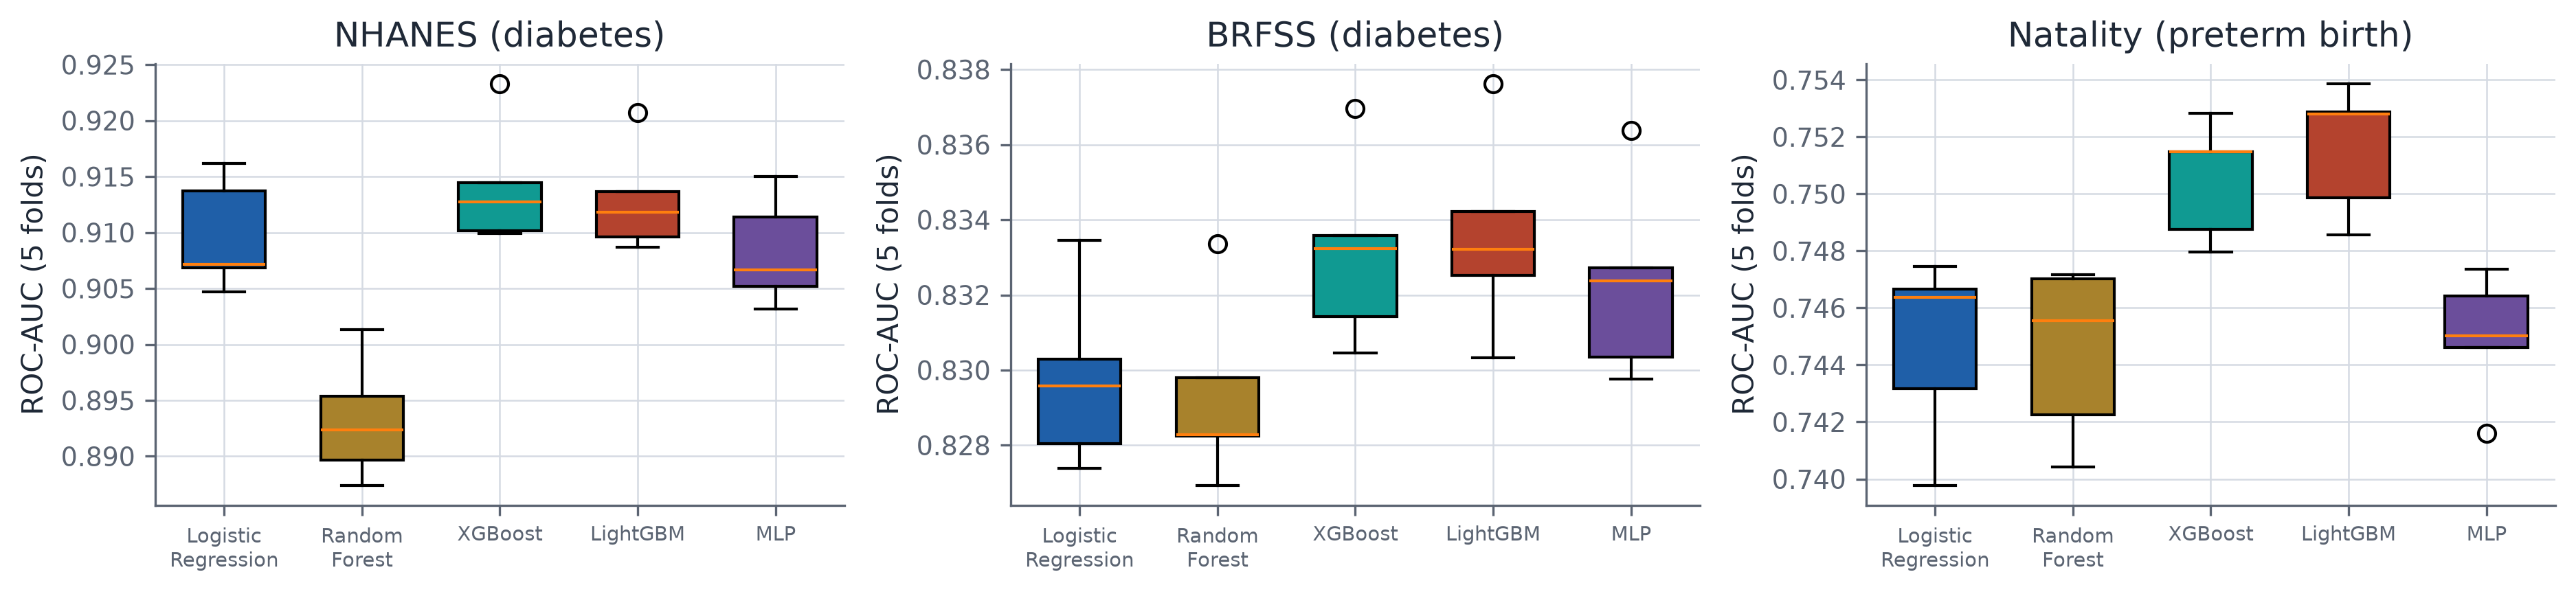

5-fold stratified cross-validation ROC-AUC on the development periods of the default split.


In [31]:
# --- from scripts/make_figures.py ---
def fig_cv():
    dss = present("cv_folds.csv")
    if not dss:
        return
    fig, axes = panels(len(dss), 3.0)
    for ax, ds in zip(axes, dss):
        f = pd.read_csv(res(ds, "cv_folds.csv"))
        data = [f.loc[f["model"] == m, "roc_auc"].values for m in MODELS]
        bp = ax.boxplot(data, patch_artist=True, widths=0.6)
        for patch, m in zip(bp["boxes"], MODELS):
            patch.set_facecolor(MODEL_COLORS[m])
        ax.set_xticks(range(1, 6), [MODEL_LABELS[m].replace(" ", "\n") for m in MODELS], fontsize=7)
        ax.set_title(NAMES[ds]); ax.set_ylabel("ROC-AUC (5 folds)")
    fig.tight_layout()
    save(fig, "fig09_cross_validation",
         "5-fold stratified cross-validation ROC-AUC on the development periods of the default split.")


fig_cv()
show("fig09_cross_validation")

Fold-to-fold standard deviations are small (<= 0.005 ROC-AUC): in-period performance is stable.
GBDTs are also best within periods.

## 9. Model evaluation

For every model and split we compute accuracy, precision, recall, F1, ROC-AUC, PR-AUC, the Brier
score and the confusion matrix, at threshold 0.5 and at the validation-tuned threshold.
**ROC-AUC** is the main metric (as in TabReD for classification): it does not depend on the
threshold or on the prevalence, which changes between periods. **PR-AUC** is reported because
positives are rare, and the threshold metrics show the clinical trade-off between missed cases and
false alarms.

**Uncertainty.** 95% bootstrap confidence intervals (1,000 resamples of the test rows) for ROC-AUC
and PR-AUC; a **paired** bootstrap (both models scored on the same resamples) for differences
between models on the same test set; an **unpaired** bootstrap for differences between two
different test sets (random vs time).

### 9.1 Default time split: all metrics on the test periods

In [32]:
# --- from scripts/summarize_benchmarks.py ---
def datasets_table(present) -> pd.DataFrame:
    """Rows, features and positive rate (first -> last period) of every dataset."""
    rows = []
    for ds in present:
        data, num, cat = load_dataset(ds)
        per = data.groupby("cycle")["label"].mean().reindex(DATASETS[ds]["periods"])
        rows.append({"dataset": INFO[ds][0], "source": INFO[ds][2], "target": INFO[ds][1],
                     "rows": len(data), "features": len(num) + len(cat), "numeric": len(num),
                     "categorical": len(cat), "periods": len(per),
                     "positive_rate": f"{data['label'].mean():.1%} ({per.iloc[0]:.1%} -> {per.iloc[-1]:.1%})"})
    return pd.DataFrame(rows)


def test_auc_table(present) -> pd.DataFrame:
    """Test ROC-AUC of every model on every split (one row per dataset x model)."""
    frames = []
    for ds in present:
        m = read(ds, "metrics.csv")
        m = m[(m["split"] == "test") & (m["threshold_rule"] == "val_f1")]
        piv = m.pivot_table(index="model", columns="protocol", values="roc_auc").reindex(MODELS)
        piv = piv[[s for s in SPLITS if s in piv.columns]]
        piv.insert(0, "dataset", ds)
        frames.append(piv.reset_index())
    return pd.concat(frames, ignore_index=True)


def default_metrics_table(present) -> pd.DataFrame:
    """Default time split: all course metrics on the test periods with bootstrap CIs."""
    frames = []
    for ds in present:
        m = read(ds, "metrics.csv")
        m = m[(m["protocol"] == "default") & (m["split"] == "test") & (m["threshold_rule"] == "val_f1")]
        ci = read(ds, "default_test_ci.csv")
        t = m.merge(ci.drop(columns=["roc_auc", "pr_auc", "dataset"]), on="model")
        t["ROC-AUC [95% CI]"] = t.apply(lambda r: f"{r.roc_auc:.3f} [{r.roc_auc_low:.3f}, {r.roc_auc_high:.3f}]", axis=1)
        t["PR-AUC [95% CI]"] = t.apply(lambda r: f"{r.pr_auc:.3f} [{r.pr_auc_low:.3f}, {r.pr_auc_high:.3f}]", axis=1)
        sel = (ROOT / DATASETS[ds]["out"] / "default_selected_model.txt").read_text().strip()
        t["selected_on_val"] = t["model"] == sel
        frames.append(t[["dataset", "model", "accuracy", "precision", "recall", "f1", "ROC-AUC [95% CI]",
                         "PR-AUC [95% CI]", "threshold", "selected_on_val"]])
    return pd.concat(frames, ignore_index=True)


def paired_table(present) -> pd.DataFrame:
    paired = [read(ds, "default_paired_comparisons.csv") for ds in present]
    return pd.concat([p for p in paired if p is not None], ignore_index=True)


ALL_DS = list(DATASETS)
default_metrics = default_metrics_table(ALL_DS)
default_metrics.to_csv(SUMMARY_DIR / "default_test_metrics.csv", index=False)
display(default_metrics.round(3))

,dataset,model,accuracy,precision,recall,f1,ROC-AUC [95% CI],PR-AUC [95% CI],threshold,selected_on_val
0,nhanes,logreg,0.849,0.515,0.720,0.601,"0.882 [0.872, 0.891]","0.619 [0.594, 0.645]",0.714,False
1,nhanes,random_forest,0.829,0.471,0.707,0.566,"0.876 [0.867, 0.884]","0.571 [0.544, 0.597]",0.468,False
2,nhanes,xgboost,0.868,0.571,0.659,0.612,"0.900 [0.892, 0.908]","0.654 [0.630, 0.677]",0.727,False
3,nhanes,lightgbm,0.861,0.548,0.675,0.605,"0.899 [0.892, 0.906]","0.646 [0.622, 0.669]",0.714,False
4,nhanes,mlp,0.863,0.555,0.671,0.607,"0.887 [0.878, 0.895]","0.634 [0.608, 0.661]",0.718,True
5,brfss,logreg,0.801,0.365,0.608,0.456,"0.822 [0.819, 0.825]","0.409 [0.401, 0.418]",0.641,False
6,brfss,random_forest,0.804,0.368,0.586,0.452,"0.821 [0.818, 0.825]","0.409 [0.401, 0.418]",0.545,False
7,brfss,xgboost,0.811,0.377,0.582,0.458,"0.824 [0.821, 0.827]","0.418 [0.410, 0.427]",0.663,True
8,brfss,lightgbm,0.814,0.383,0.573,0.459,"0.826 [0.823, 0.829]","0.422 [0.414, 0.431]",0.682,False
9,brfss,mlp,0.808,0.375,0.588,0.458,"0.824 [0.821, 0.827]","0.415 [0.406, 0.423]",0.689,False


saved fig02_default_auc_ci


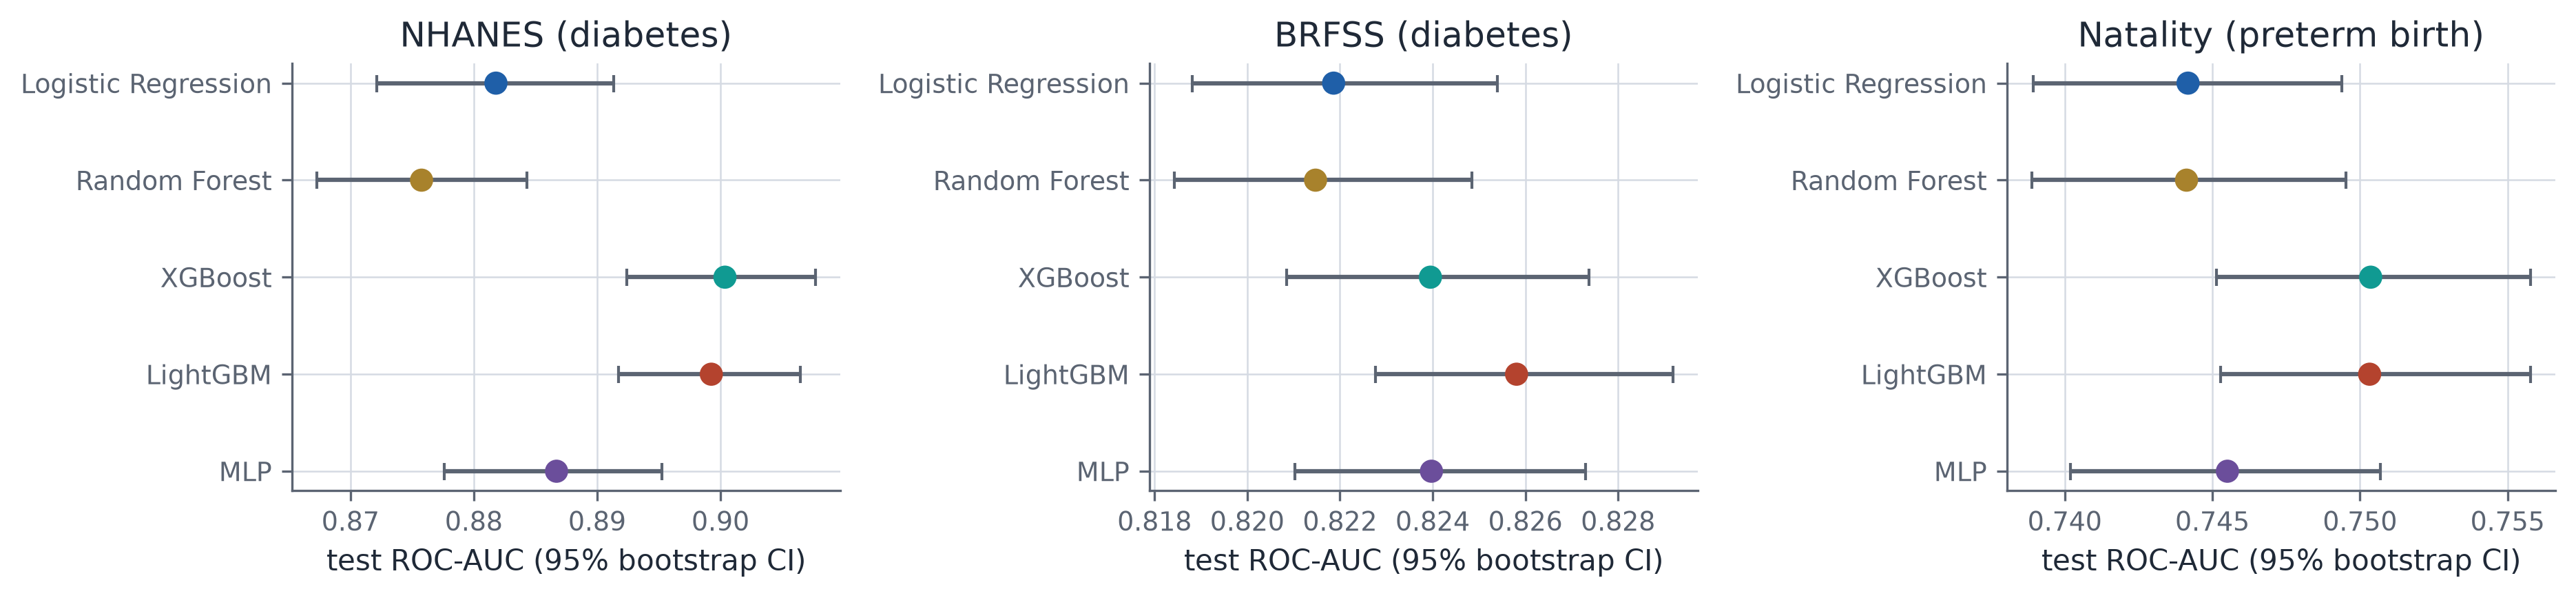

Default time split: test ROC-AUC per model with 95% bootstrap confidence intervals.


In [33]:
# --- from scripts/make_figures.py ---
def fig_auc_ci():
    dss = present("default_test_ci.csv")
    fig, axes = panels(len(dss), 3.0)
    for ax, ds in zip(axes, dss):
        ci = pd.read_csv(res(ds, "default_test_ci.csv")).set_index("model").reindex(MODELS)
        y = np.arange(len(MODELS))
        ax.errorbar(ci["roc_auc"], y, xerr=[ci["roc_auc"] - ci["roc_auc_low"], ci["roc_auc_high"] - ci["roc_auc"]],
                    fmt="none", ecolor=MUTED, capsize=3)
        ax.scatter(ci["roc_auc"], y, c=[MODEL_COLORS[m] for m in MODELS], s=50, zorder=3)
        ax.set_yticks(y, [MODEL_LABELS[m] for m in MODELS]); ax.invert_yaxis()
        ax.set_title(NAMES[ds]); ax.set_xlabel("test ROC-AUC (95% bootstrap CI)")
    fig.tight_layout()
    save(fig, "fig02_default_auc_ci", "Default time split: test ROC-AUC per model with 95% bootstrap confidence intervals.")


fig_auc_ci()
show("fig02_default_auc_ci")

Paired bootstrap differences: the model selected on validation minus every other model, on the same
test rows (`ci_excludes_zero` = the difference is significant at 95%):

In [34]:
paired = paired_table(ALL_DS)
paired.to_csv(SUMMARY_DIR / "default_paired_comparisons.csv", index=False)
display(paired[paired["metric"] == "roc_auc"].round(4))

,reference,other,metric,diff,diff_low,diff_high,ci_excludes_zero,dataset
0,mlp,lightgbm,roc_auc,-0.0125,-0.0193,-0.0058,True,nhanes
2,mlp,logreg,roc_auc,0.0049,0.0022,0.0078,True,nhanes
4,mlp,random_forest,roc_auc,0.0109,0.0030,0.0186,True,nhanes
6,mlp,xgboost,roc_auc,-0.0137,-0.0203,-0.0069,True,nhanes
8,xgboost,lightgbm,roc_auc,-0.0019,-0.0026,-0.0011,True,brfss
10,xgboost,logreg,roc_auc,0.0021,0.0009,0.0032,True,brfss
12,xgboost,mlp,roc_auc,-0.0000,-0.0010,0.0010,False,brfss
14,xgboost,random_forest,roc_auc,0.0025,0.0014,0.0036,True,brfss
16,xgboost,lightgbm,roc_auc,0.0000,-0.0008,0.0008,False,natality
18,xgboost,logreg,roc_auc,0.0062,0.0044,0.0080,True,natality


* **GBDTs are best on all three datasets** (XGBoost / LightGBM). The differences are small in
  absolute terms but significant with the paired bootstrap.
* **The feature-rich dataset separates models most:** NHANES (280 features) spans 0.876-0.900
  ROC-AUC, BRFSS (93) and natality (73) only about 0.005.
* In NHANES the model selected on the validation period (the MLP) is significantly worse than
  XGBoost and LightGBM on the later test years: choosing a model on one period does not guarantee
  the best model for the next.

### 9.2 ROC curves and confusion matrices

saved fig04_roc_curves


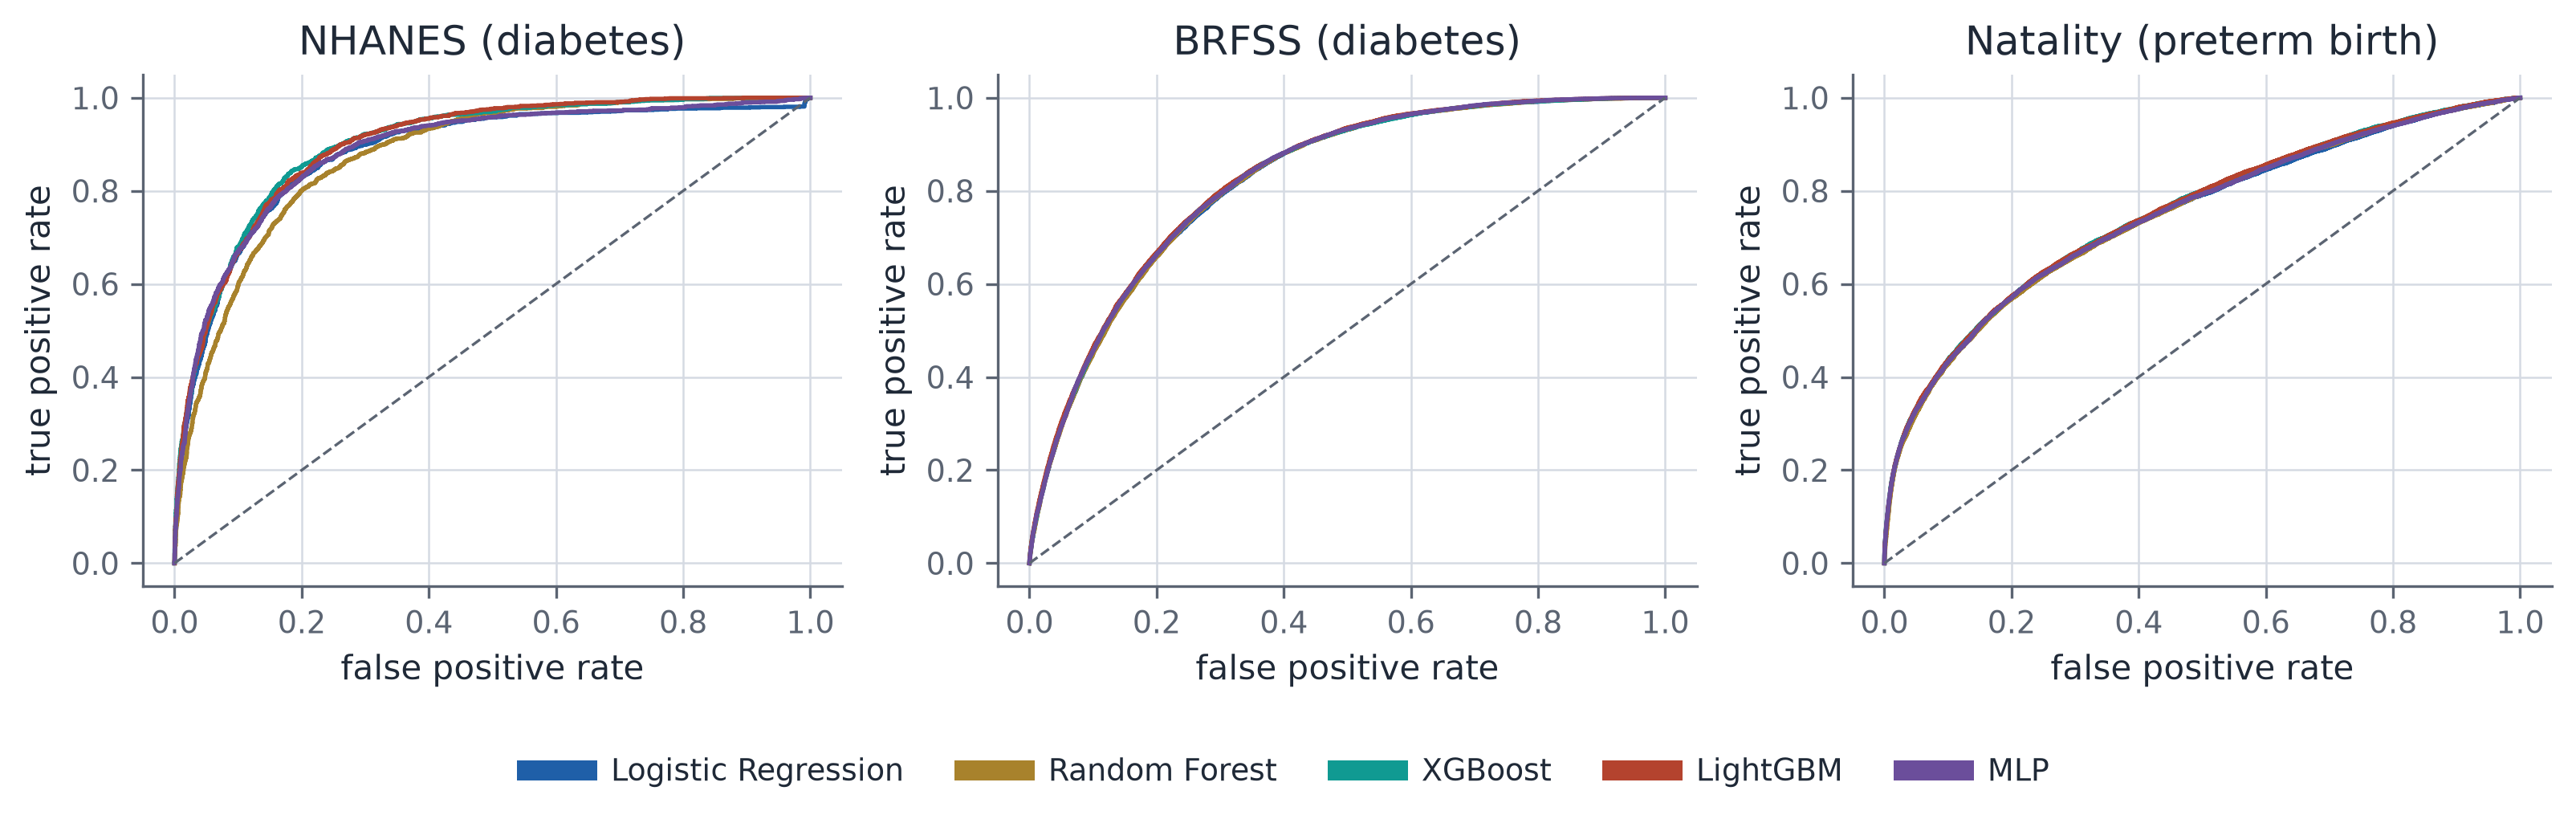

ROC curves on the default split's test periods.


saved fig05_confusion_matrices


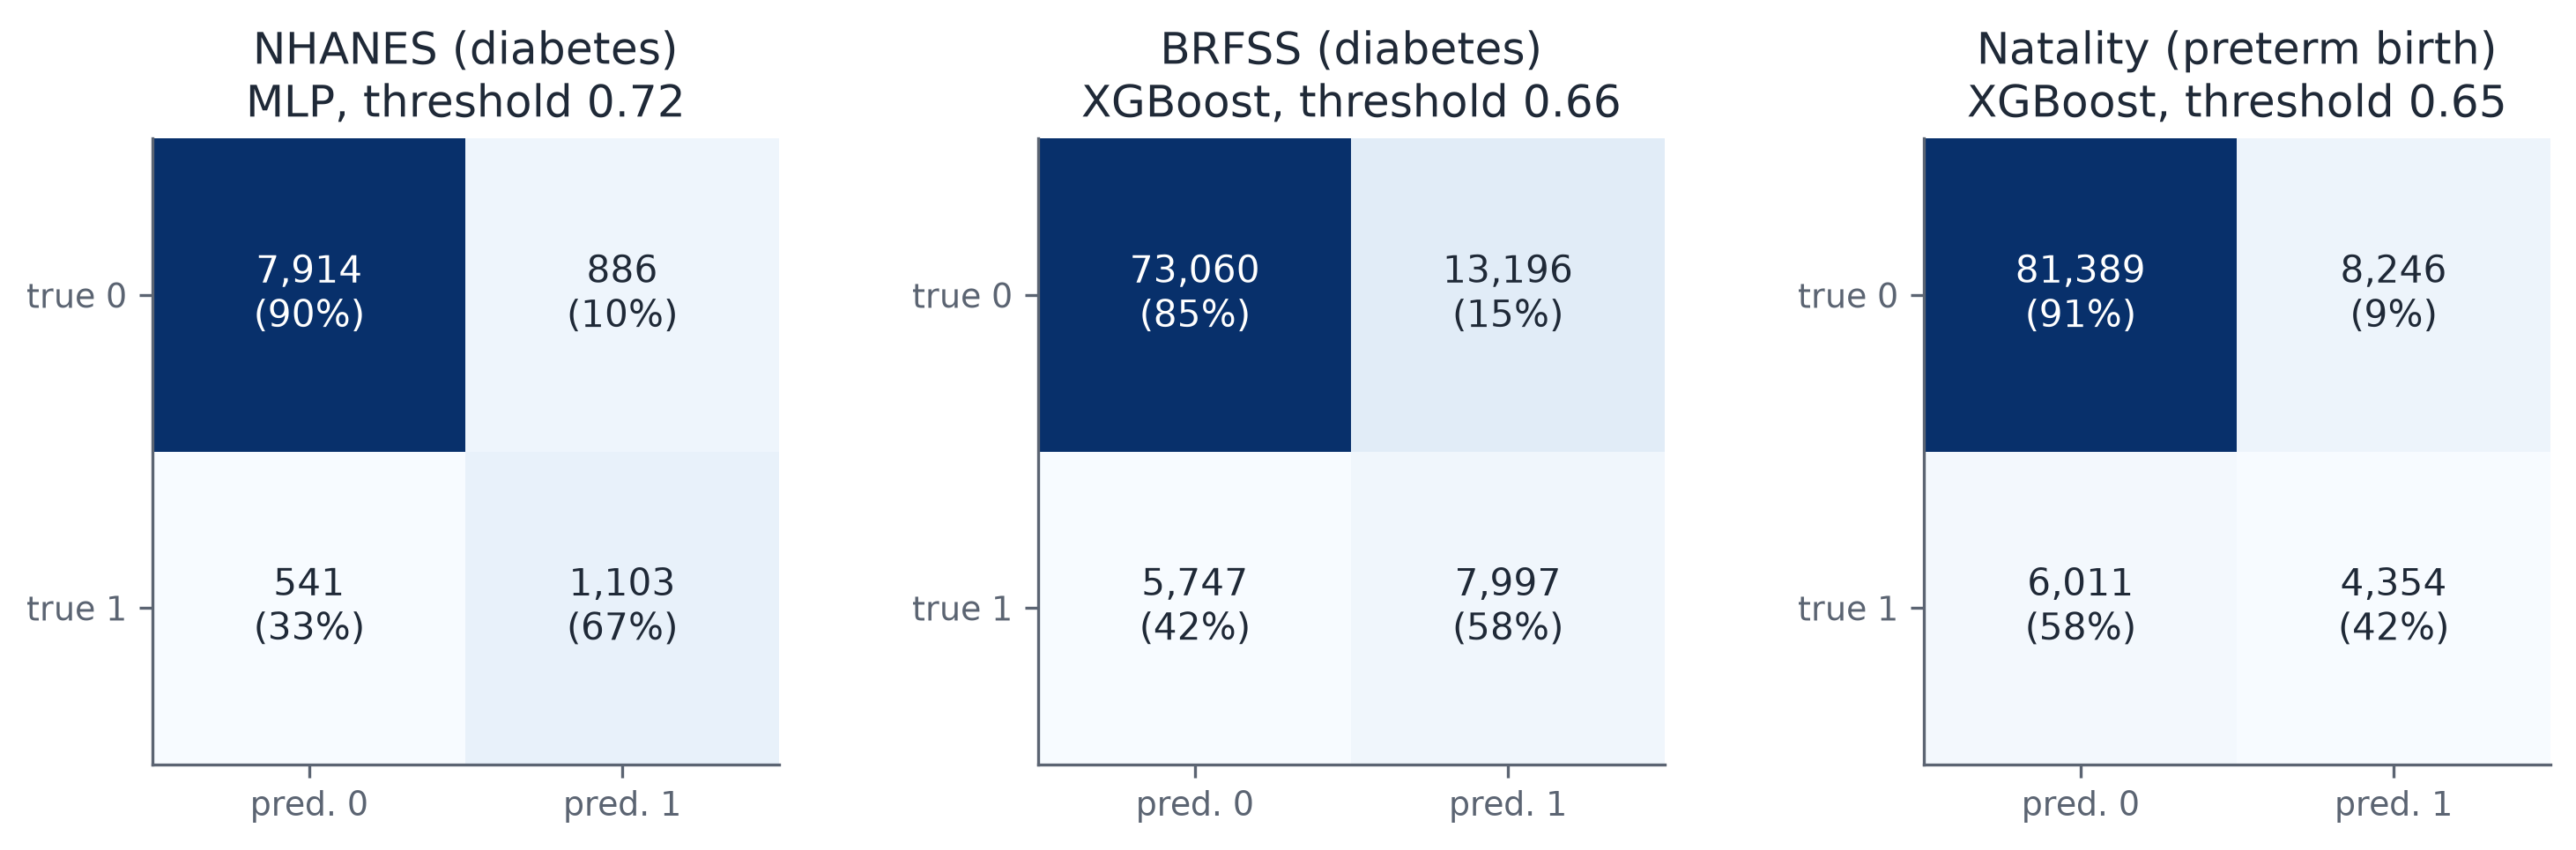

Confusion matrices of the validation-selected model on the default split's test periods (threshold = max F1 on validation; row percentages).


In [35]:
# --- from scripts/make_figures.py ---
def fig_roc():
    dss = present("predictions/test_predictions.csv")
    fig, axes = panels(len(dss), 3.4, 3.6)
    for ax, ds in zip(axes, dss):
        p = pd.read_csv(res(ds, "predictions/test_predictions.csv"))
        p = p[p["protocol"] == "default"]
        for m in MODELS:
            q = p[p["model"] == m]
            fpr, tpr, _ = roc_curve(q["label"], q["probability"])
            ax.plot(fpr, tpr, color=MODEL_COLORS[m], lw=1.3)
        ax.plot([0, 1], [0, 1], ls="--", color=MUTED, lw=0.8)
        ax.set_title(NAMES[ds]); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    model_legend(fig)
    save(fig, "fig04_roc_curves", "ROC curves on the default split's test periods.")


def fig_confusion():
    dss = present("predictions/test_predictions.csv")
    fig, axes = panels(len(dss), 3.2, 3.4)
    for ax, ds in zip(axes, dss):
        best = res(ds, "default_selected_model.txt").read_text().strip()
        thr = json.loads(res(ds, "selected_models.json").read_text())["default"][best]["threshold"]
        p = pd.read_csv(res(ds, "predictions/test_predictions.csv"))
        q = p[(p["protocol"] == "default") & (p["model"] == best)]
        cm = confusion_matrix(q["label"], q["probability"] >= thr)
        ax.imshow(cm, cmap="Blues"); ax.grid(False)
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, f"{v:,}\n({v / cm[i].sum():.0%})", ha="center", va="center",
                    color="white" if v > cm.max() / 2 else INK)
        ax.set_xticks([0, 1], ["pred. 0", "pred. 1"]); ax.set_yticks([0, 1], ["true 0", "true 1"])
        ax.set_title(f"{NAMES[ds]}\n{MODEL_LABELS[best]}, threshold {thr:.2f}")
    fig.tight_layout()
    save(fig, "fig05_confusion_matrices",
         "Confusion matrices of the validation-selected model on the default split's test periods "
         "(threshold = max F1 on validation; row percentages).")


fig_roc()
show("fig04_roc_curves")
fig_confusion()
show("fig05_confusion_matrices")

At the max-F1 threshold the selected models find about two thirds of the diabetes cases in NHANES,
about 60% in BRFSS and 35-40% of preterm births, with precision of roughly 0.5, 0.37 and 0.4: preterm
birth is much harder to predict from information available before delivery.

### 9.3 Test ROC-AUC on every split

In [36]:
auc = test_auc_table(ALL_DS)
auc.to_csv(SUMMARY_DIR / "test_roc_auc_by_split.csv", index=False)
display(auc.round(3))

protocol,model,dataset,default,sliding-window-0,sliding-window-1,sliding-window-2,random-0,random-1,random-2
0,logreg,nhanes,0.882,0.903,0.892,0.899,0.900,0.915,0.901
1,random_forest,nhanes,0.876,0.889,0.877,0.871,0.883,0.904,0.879
2,xgboost,nhanes,0.900,0.914,0.901,0.903,0.903,0.918,0.906
3,lightgbm,nhanes,0.899,0.914,0.900,0.903,0.901,0.913,0.905
4,mlp,nhanes,0.887,0.902,0.892,0.897,0.905,0.914,0.901
5,logreg,brfss,0.822,0.824,0.821,0.822,0.832,0.830,0.827
6,random_forest,brfss,0.821,0.823,0.822,0.821,0.832,0.827,0.826
7,xgboost,brfss,0.824,0.828,0.826,0.825,0.836,0.833,0.830
8,lightgbm,brfss,0.826,0.828,0.826,0.825,0.837,0.833,0.831
9,mlp,brfss,0.824,0.827,0.822,0.823,0.834,0.832,0.828


## 10. Temporal drift analysis

Drift is described in three ways:
1. **Is there covariate shift?** A *domain classifier* (logistic regression with the shared
   preprocessing, 5-fold CV, at most 20,000 rows per side) tries to tell the training periods from
   the test period. ROC-AUC 0.5 = indistinguishable; for random splits it must be ~0.5 by construction.
2. **Which features drift?** Population Stability Index (PSI, 10 quantile bins of the first period)
   and the Kolmogorov-Smirnov statistic for numeric features; total variation distance (TVD, with
   "missing" as a category) for categorical features; first vs last period, and the largest change
   between consecutive periods.
3. **Why?** Documented changes with a clinical cause (`EVENTS`: laboratory instrument changes,
   health policy, questionnaire coding revisions, reporting laws, population trends), each measured
   in every period.

In [37]:
# --- from src/clinical_tabred/drift.py ---
def psi(reference: np.ndarray, current: np.ndarray, n_bins: int) -> float:
    """Population Stability Index with quantile bins fixed on the reference period.

    PSI = sum over bins of (p_cur - p_ref) * ln(p_cur / p_ref). A common rule of
    thumb: < 0.1 small change, 0.1-0.25 moderate, > 0.25 large.
    """
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, n_bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    p_ref = np.histogram(reference, edges)[0] / len(reference)
    p_cur = np.histogram(current, edges)[0] / len(current)
    p_ref, p_cur = np.clip(p_ref, 1e-6, None), np.clip(p_cur, 1e-6, None)  # avoid log(0)
    return float(np.sum((p_cur - p_ref) * np.log(p_cur / p_ref)))


# --- from scripts/analyze_drift.py ---
# (column, statistic, code, cause type, period of the change, description)
# statistic: "mean" of the column, "share" of rows equal to `code`, "missing" share.
EVENTS = {
    "nhanes": [
        ("label", "mean", None, "label / population shift", "steady",
         "Diagnosed-diabetes prevalence rises cycle after cycle"),
        ("HIQ011", "share", 2, "policy change", "2015-2016",
         "Not covered by health insurance: falls after the 2014 Affordable Care Act coverage expansion"),
        ("HIQ031D", "mean", None, "policy change", "2015-2016",
         "Covered by Medicaid: rises with the 2014 ACA Medicaid expansion"),
        ("BMXBMI", "mean", None, "population shift", "steady", "Mean measured BMI rises (obesity trend)"),
        ("LBXRDW", "mean", None, "protocol change (lab instrument)", "2013-2014",
         "Hematology analyzer replaced by Beckman Coulter DxH 800; CDC: mean RDW 12.84% -> 13.55% (CBC_H docs)"),
        ("LBXSLDSI", "mean", None, "protocol change (lab instrument)", "2017-2018",
         "Biochemistry analyzer and lab changed to Roche Cobas 6000; CDC bridging study: LDH +14.9% (BIOPRO_J docs)"),
        ("LBXSASSI", "mean", None, "protocol change (lab instrument)", "2017-2018",
         "Same 2017-2018 analyzer change; CDC bridging study: AST -18.0% (BIOPRO_J docs)"),
    ],
    "brfss": [
        ("label", "mean", None, "population shift", "2020",
         "Diagnosed-diabetes prevalence dips in the COVID-19 year 2020"),
        ("PERSDOC", "share", 2, "coding revision", "2021",
         "PERSDOC2 -> PERSDOC3 rewording: 'more than one personal doctor' jumps"),
        ("HLTHPLN", "share", 2, "coding revision", "2021",
         "Yes/no coverage question replaced by 'primary source of insurance' (CDC-derived series)"),
        ("_HCVU65", "share", 2, "coding revision", "2021",
         "CDC-derived 'no coverage, age 18-64' follows the same 2021 question change"),
        ("_MRACE", "share", 6, "coding revision", "2022",
         "2022 race question: 'other race only' category removed"),
        ("MSCODE", "missing", None, "survey-mode change", "steady",
         "Landline-only metro code: missing grows as the sample shifts to cell phones"),
    ],
    "natality": [
        ("label", "mean", None, "label shift", "2021",
         "Preterm-birth rate rises to a 2021 peak"),
        ("DMAR", "missing", None, "reporting change (state law)", "2017",
         "Marital status withheld for California births from 2017"),
        ("RF_GHYPE", "mean", None, "population / diagnostic practice", "steady",
         "Gestational hypertension nearly doubles"),
        ("RF_PHYPE", "mean", None, "population / diagnostic practice", "steady",
         "Pre-pregnancy hypertension doubles"),
        ("RF_GDIAB", "mean", None, "population / diagnostic practice", "steady",
         "Gestational diabetes rises"),
        ("CIG_0", "mean", None, "population shift", "steady",
         "Cigarettes per day before pregnancy fall by about two thirds"),
        ("FAGECOMB", "missing", None, "protocol change (COVID-19)", "2020",
         "Hospital COVID-19 policies: more births with unknown father information (NCHS User Guide)"),
    ],
}


MAX_ROWS = 20_000


def domain_auc(a: pd.DataFrame, b: pd.DataFrame, numeric, categorical, seed: int) -> float:
    """5-fold CV ROC-AUC of a logistic regression telling rows of `b` from rows of `a`."""
    a = a.sample(n=min(len(a), MAX_ROWS), random_state=seed)
    b = b.sample(n=min(len(b), MAX_ROWS), random_state=seed)
    both = pd.concat([a, b], ignore_index=True)
    y = np.r_[np.zeros(len(a)), np.ones(len(b))]
    model = Pipeline([("prep", make_preprocessor(numeric, categorical)),
                      ("model", LogisticRegression(max_iter=2000))])
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    return float(cross_val_score(model, feature_matrix(both, numeric + categorical), y, cv=folds,
                                 scoring="roc_auc").mean())


def tvd(a: pd.Series, b: pd.Series) -> float:
    """Total variation distance between two categorical distributions (missing = a category)."""
    pa = a.fillna(-1).value_counts(normalize=True)
    pb = b.fillna(-1).value_counts(normalize=True)
    return float(0.5 * pa.subtract(pb, fill_value=0).abs().sum())


def feature_drift(data, numeric, categorical, periods) -> pd.DataFrame:
    first, last = data[data["cycle"] == periods[0]], data[data["cycle"] == periods[-1]]
    rows = []
    for f in numeric + categorical:
        a, b = first[f], last[f]
        row = {"feature": f, "type": "numeric" if f in numeric else "categorical",
               "first": periods[0], "last": periods[-1],
               "missing_first": a.isna().mean(), "missing_last": b.isna().mean()}
        if f in numeric and a.notna().sum() > 50 and b.notna().sum() > 50:
            row.update(mean_first=a.mean(), mean_last=b.mean(),
                       ks=ks_2samp(a.dropna(), b.dropna()).statistic,
                       psi=psi(a.dropna().to_numpy(), b.dropna().to_numpy(), 10))
        row["tvd"] = tvd(a, b) if f in categorical else np.nan
        # largest change between consecutive periods: TVD (categorical) / PSI (numeric)
        steps = []
        for p, q in zip(periods[:-1], periods[1:]):
            x, z = data.loc[data["cycle"] == p, f], data.loc[data["cycle"] == q, f]
            if f in categorical:
                steps.append(tvd(x, z))
            elif x.notna().sum() > 50 and z.notna().sum() > 50:
                steps.append(psi(x.dropna().to_numpy(), z.dropna().to_numpy(), 10))
            else:
                steps.append(0.0)
        k = int(np.argmax(steps))
        row.update(max_step=steps[k], max_step_between=f"{periods[k]}->{periods[k + 1]}")
        rows.append(row)
    out = pd.DataFrame(rows)
    out["drift_score"] = out["psi"].fillna(out["tvd"])
    return out.sort_values("drift_score", ascending=False)


def event_table(data, events, periods) -> pd.DataFrame:
    rows = []
    for col, stat, code, cause, when, desc in events:
        if col not in data:
            continue
        values = {}
        for p in periods:
            x = data.loc[data["cycle"] == p, col]
            values[p] = (x.mean() if stat == "mean" else (x == code).mean() if stat == "share"
                         else x.isna().mean())
        rows.append({"feature": col, "statistic": stat if code is None else f"share == {code}",
                     "cause": cause, "change_at": when, "description": desc, **values})
    return pd.DataFrame(rows)


def domain_table(data, splits, numeric, categorical, periods, seed: int, verbose: bool = True) -> pd.DataFrame:
    """Domain-classifier ROC-AUC: train vs test of every split, and each pair of adjacent periods."""
    dom = []
    for name, parts in splits.items():
        auc = domain_auc(parts["train"], parts["test"], numeric, categorical, seed)
        dom.append({"comparison": f"{name}: train vs test", "kind": "random" if name.startswith("random")
                    else "time", "split": name, "roc_auc": auc})
        if verbose:
            print(f"domain {name:18s} train vs test ROC-AUC {auc:.3f}", flush=True)
    for p, q in zip(periods[:-1], periods[1:]):
        auc = domain_auc(data[data["cycle"] == p], data[data["cycle"] == q], numeric, categorical, seed)
        dom.append({"comparison": f"{p} vs {q}", "kind": "adjacent", "split": "", "roc_auc": auc})
        if verbose:
            print(f"domain {p} vs {q} ROC-AUC {auc:.3f}", flush=True)
    return pd.DataFrame(dom)


def drift_performance(gaps: pd.DataFrame, splits, dom: pd.DataFrame, events: pd.DataFrame, spec: dict) -> pd.DataFrame:
    """One row per sliding window: time vs random test ROC-AUC next to the drift measured for it."""
    periods = spec["periods"]
    gaps = gaps[gaps["metric"] == "roc_auc"]
    rows = []
    for k, start in enumerate(spec["windows"]):
        g = gaps[gaps["window"] == k]
        w = splits[f"sliding-window-{k}"]
        test_p = periods[start + 4]
        hit = events[events["change_at"].isin([test_p])]["description"].tolist() if not events.empty else []
        rows.append({"window": k, "train": f"{periods[start]}..{periods[start + 2]}",
                     "val": periods[start + 3], "test": test_p,
                     "time_roc_auc_mean": g["time"].mean(), "random_roc_auc_mean": g["random"].mean(),
                     "random_minus_time_mean": g["diff"].mean(),
                     "models_gap_significant": int(g["ci_excludes_zero"].sum()), "n_models": len(g),
                     "domain_auc_time": dom.loc[dom["split"] == f"sliding-window-{k}", "roc_auc"].item(),
                     "domain_auc_random": dom.loc[dom["split"] == f"random-{k}", "roc_auc"].item(),
                     "prevalence_train": w["train"]["label"].mean(),
                     "prevalence_test": w["test"]["label"].mean(),
                     "events_in_test_period": " | ".join(hit)})
    return pd.DataFrame(rows)


def run_drift(dataset: str, verbose: bool = True) -> dict[str, pd.DataFrame]:
    """All drift tables of one dataset; written to its results directory."""
    config = yaml.safe_load((ROOT / "configs" / "experiment.yaml").read_text())
    seed, spec = config["seed"], DATASETS[dataset]
    out = ROOT / spec["out"]
    periods = spec["periods"]
    data, numeric, categorical = load_dataset(dataset)
    tables = {"drift_periods": period_table(data, periods)}
    tables["drift_periods"].to_csv(out / "drift_periods.csv")

    splits = make_splits(data, seed, spec)
    tables["drift_domain"] = domain_table(data, splits, numeric, categorical, periods, seed, verbose)
    tables["drift_features"] = feature_drift(data, numeric, categorical, periods)
    tables["drift_events"] = event_table(data, EVENTS[dataset], periods)
    for name in ["drift_domain", "drift_features", "drift_events"]:
        tables[name].to_csv(out / f"{name}.csv", index=False)
    gaps_file = out / "random_minus_time_by_window.csv"
    if gaps_file.exists():
        tables["drift_performance"] = drift_performance(pd.read_csv(gaps_file), splits, tables["drift_domain"],
                                                        tables["drift_events"], spec)
        tables["drift_performance"].to_csv(out / "drift_performance.csv", index=False)
    return tables

In [38]:
if RUN_EXPERIMENTS:
    for ds in DATASETS:
        run_drift(ds)
for ds in DATASETS:   # documented events: recomputed here from the tables (fast)
    ev = event_table(DATA[ds][0], EVENTS[ds], DATASETS[ds]["periods"])
    ev.to_csv(SUMMARY_DIR / f"drift_events_{ds}.csv", index=False)
    print(ds); display(ev.set_index("feature").round(4))

nhanes


,statistic,cause,change_at,description,2005-2006,2007-2008,2009-2010,2011-2012,2013-2014,2015-2016,2017-2018
feature,,,,,,,,,,,
label,mean,label / population shift,steady,Diagnosed-diabetes prevalence rises cycle after cycle,0.1036,0.1289,0.1205,0.1300,0.1305,0.1511,0.1640
HIQ011,share == 2,policy change,2015-2016,Not covered by health insurance: falls after the 2014 Affordable Care Act coverage exp...,0.2215,0.2379,0.2564,0.2386,0.2131,0.1745,0.1520
HIQ031D,mean,policy change,2015-2016,Covered by Medicaid: rises with the 2014 ACA Medicaid expansion,0.0758,0.0788,0.0805,0.1113,0.1143,0.1279,0.1756
BMXBMI,mean,population shift,steady,Mean measured BMI rises (obesity trend),28.7068,28.9089,29.1100,28.7096,29.0187,29.4982,29.7966
LBXRDW,mean,protocol change (lab instrument),2013-2014,Hematology analyzer replaced by Beckman Coulter DxH 800; CDC: mean RDW 12.84% -> 13.55...,12.9040,12.9221,12.9462,13.0671,13.7263,13.8358,13.8885
LBXSLDSI,mean,protocol change (lab instrument),2017-2018,Biochemistry analyzer and lab changed to Roche Cobas 6000; CDC bridging study: LDH +14...,129.2350,133.2029,133.1429,128.5770,126.4228,129.4744,159.3282
LBXSASSI,mean,protocol change (lab instrument),2017-2018,Same 2017-2018 analyzer change; CDC bridging study: AST -18.0% (BIOPRO_J docs),25.4552,26.5599,26.3853,25.6877,25.4716,25.8765,22.0080


brfss


,statistic,cause,change_at,description,2017,2018,2019,2020,2021,2022,2023
feature,,,,,,,,,,,
label,mean,population shift,2020,Diagnosed-diabetes prevalence dips in the COVID-19 year 2020,0.1366,0.1397,0.1368,0.1304,0.1321,0.1362,0.1387
PERSDOC,share == 2,coding revision,2021,PERSDOC2 -> PERSDOC3 rewording: 'more than one personal doctor' jumps,0.0767,0.0780,0.0793,0.0670,0.2836,0.3038,0.3261
HLTHPLN,share == 2,coding revision,2021,Yes/no coverage question replaced by 'primary source of insurance' (CDC-derived series),0.0783,0.0800,0.0849,0.0857,0.0517,0.0515,0.0535
_HCVU65,share == 2,coding revision,2021,"CDC-derived 'no coverage, age 18-64' follows the same 2021 question change",0.0722,0.0735,0.0783,0.0785,0.0487,0.0485,0.0503
_MRACE,share == 6,coding revision,2022,2022 race question: 'other race only' category removed,0.0213,0.0263,0.0304,0.0303,0.0289,0.0000,0.0202
MSCODE,missing,survey-mode change,steady,Landline-only metro code: missing grows as the sample shifts to cell phones,0.5736,0.6293,0.6504,0.6979,0.7387,0.7876,0.8050


natality


,statistic,cause,change_at,description,2016,2017,2018,2019,2020,2021,2022,2023,2024
feature,,,,,,,,,,,,,
label,mean,label shift,2021,Preterm-birth rate rises to a 2021 peak,0.0964,0.0982,0.0989,0.1011,0.1031,0.1067,0.1047,0.1025,0.1048
DMAR,missing,reporting change (state law),2017,Marital status withheld for California births from 2017,0.0000,0.1214,0.1241,0.1196,0.1175,0.1151,0.1120,0.1122,0.1103
RF_GHYPE,mean,population / diagnostic practice,steady,Gestational hypertension nearly doubles,0.0585,0.0629,0.0708,0.0777,0.0858,0.0917,0.0955,0.1015,0.1032
RF_PHYPE,mean,population / diagnostic practice,steady,Pre-pregnancy hypertension doubles,0.0174,0.0191,0.0206,0.0230,0.0255,0.0276,0.0288,0.0316,0.0338
RF_GDIAB,mean,population / diagnostic practice,steady,Gestational diabetes rises,0.0589,0.0616,0.0674,0.0707,0.0803,0.0832,0.0814,0.0825,0.0851
CIG_0,mean,population shift,steady,Cigarettes per day before pregnancy fall by about two thirds,1.2258,1.1595,1.1140,1.0279,0.9602,0.7487,0.5879,0.4931,0.3852
FAGECOMB,missing,protocol change (COVID-19),2020,Hospital COVID-19 policies: more births with unknown father information (NCHS User Guide),0.1186,0.1179,0.1161,0.1162,0.1261,0.1106,0.1059,0.1037,0.0985


saved fig08_drift_events


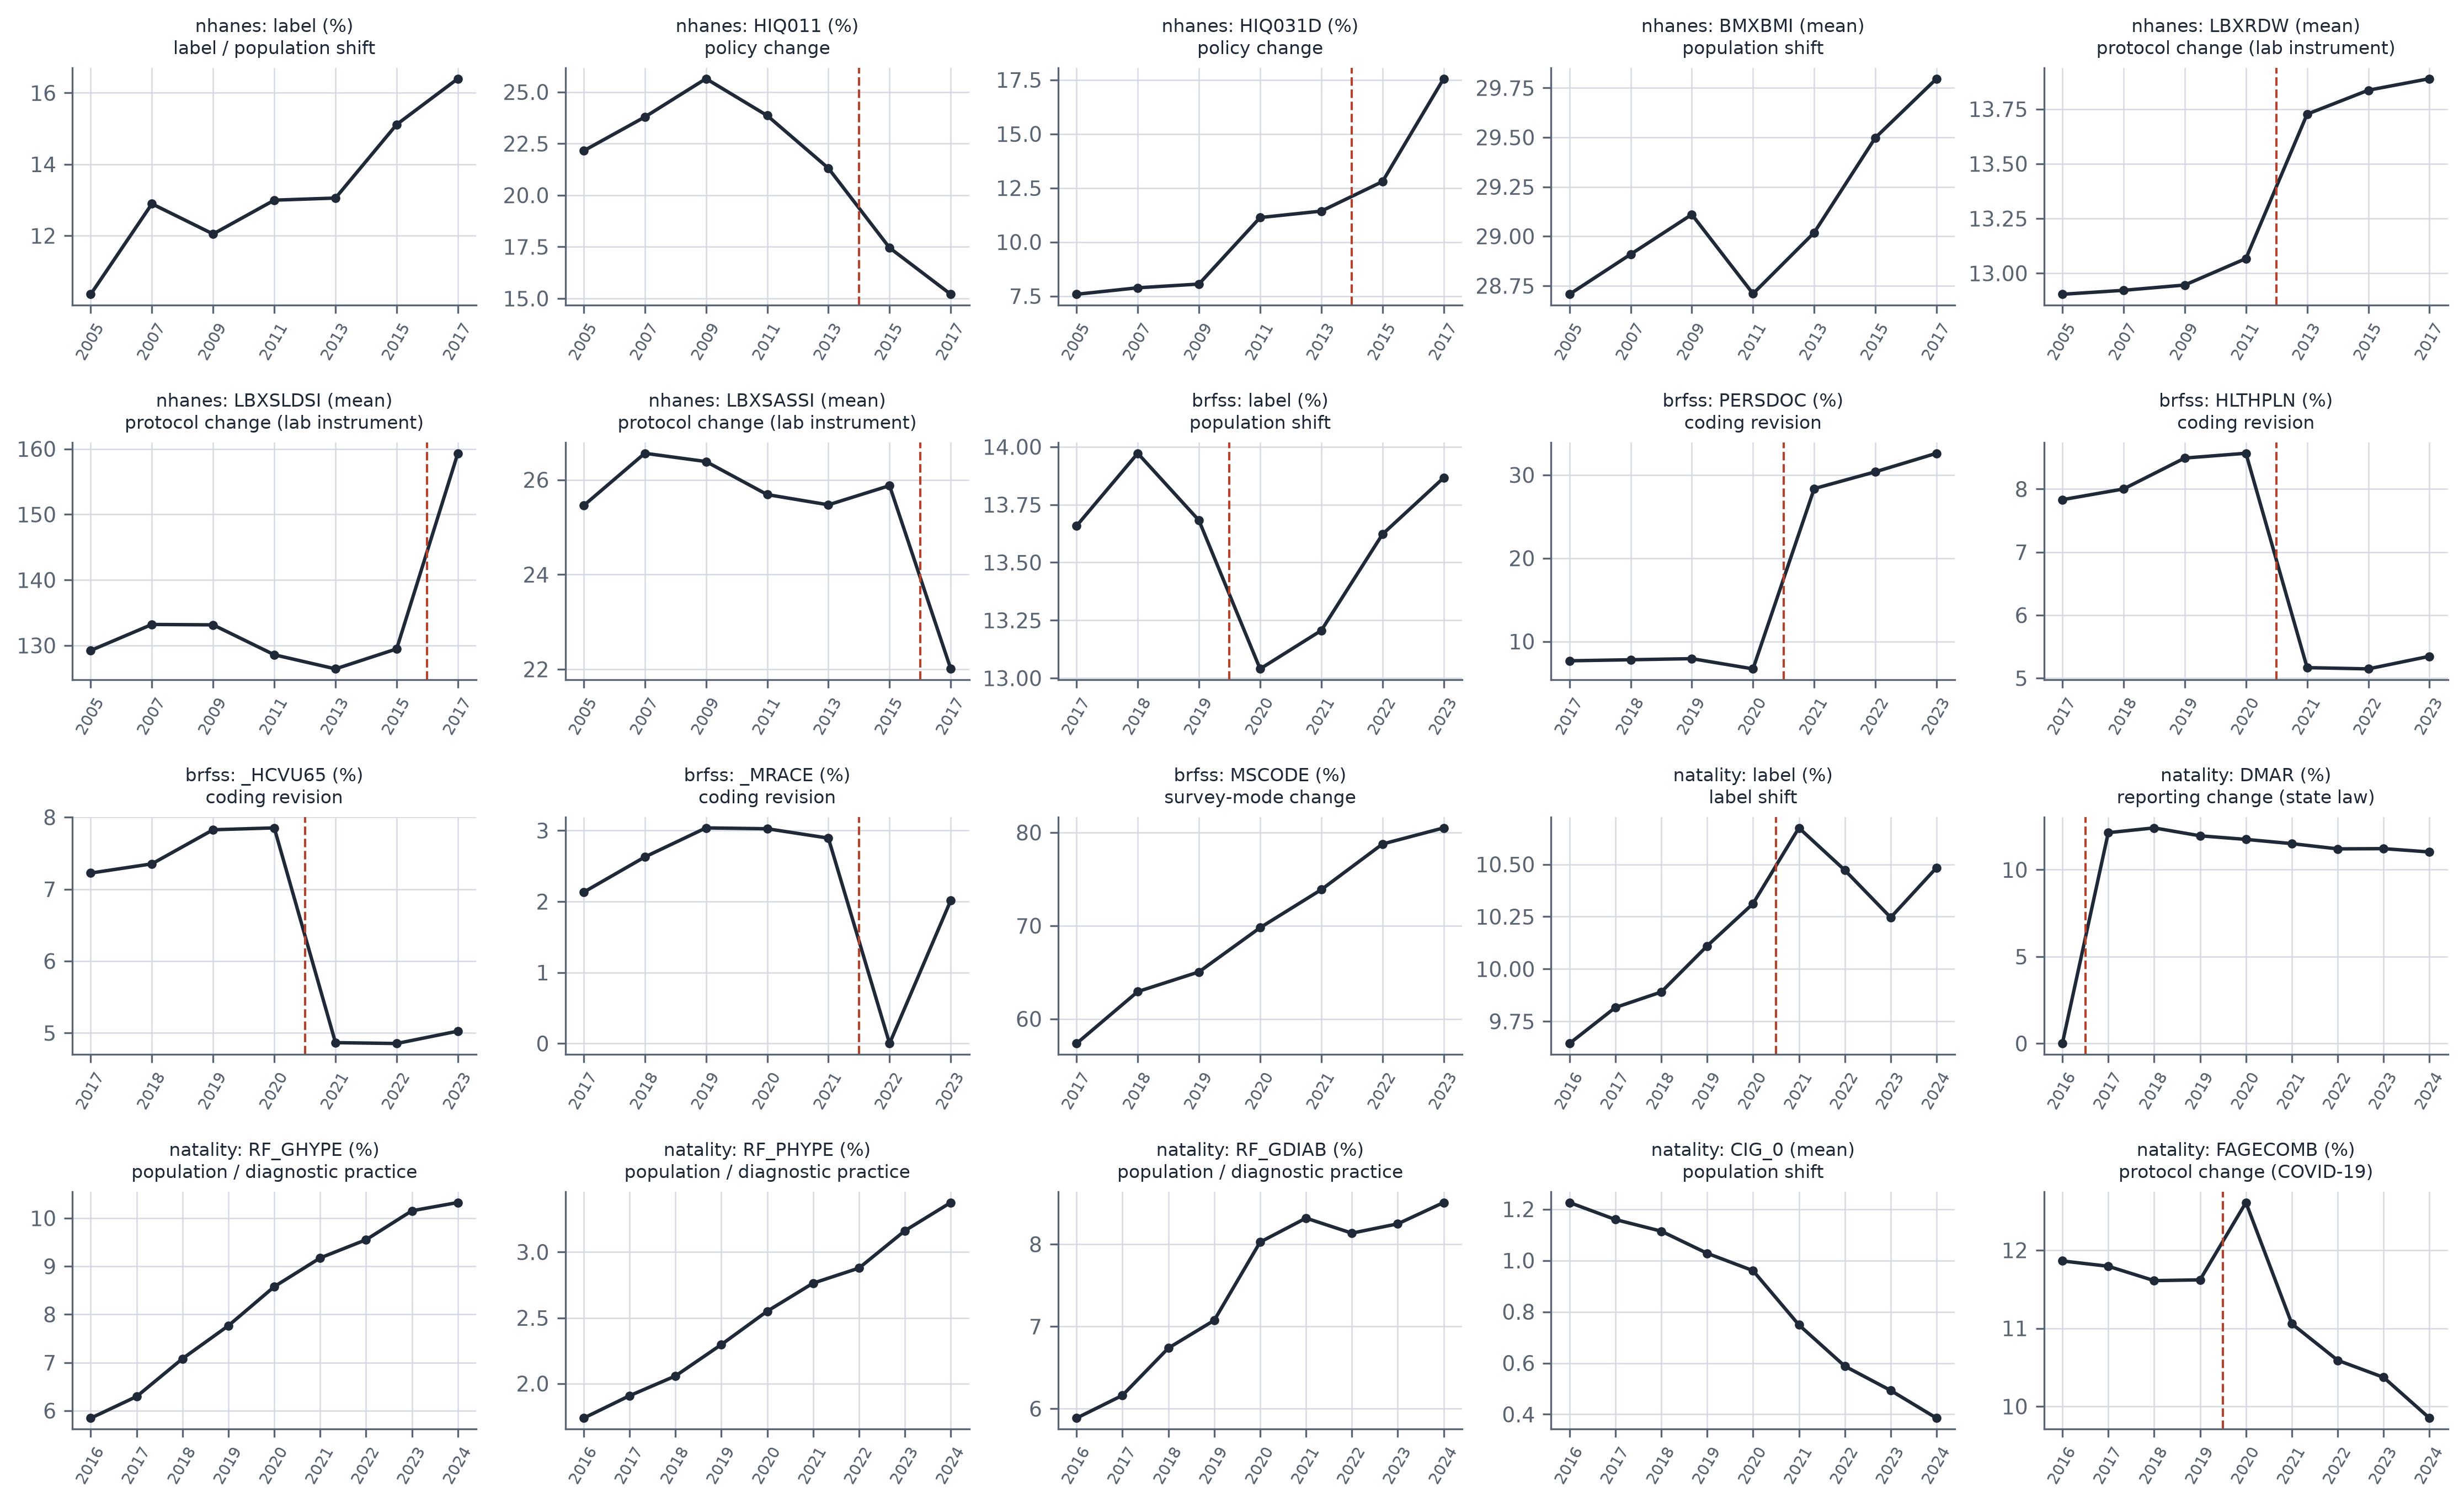

Drift with a documented clinical cause, measured per period (dashed line = period of the change).


In [39]:
# --- from scripts/make_figures.py ---
def fig_events():
    items = []
    for ds in present("drift_events.csv"):
        e = pd.read_csv(res(ds, "drift_events.csv"))
        cols = [c for c in e.columns if c[:4].isdigit()]
        for _, r in e.iterrows():
            items.append((ds, r, cols))
    n = len(items)
    ncol = 5
    nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.0 * ncol, 2.3 * nrow), squeeze=False)
    for ax, (ds, r, cols) in zip(axes.flat, items):
        v = r[cols].astype(float).values
        scale = 100 if r["statistic"] != "mean" or r["feature"] in ("label",) or v.max() <= 1 else 1
        ax.plot(range(len(cols)), v * scale, marker="o", color=INK, ms=3)
        if str(r["change_at"]) in cols:
            ax.axvline(cols.index(str(r["change_at"])) - 0.5, color=MODEL_COLORS["lightgbm"], ls="--", lw=1)
        ax.set_xticks(range(len(cols)), [c[:4] for c in cols], rotation=60, fontsize=7)
        unit = "%" if scale == 100 else "mean"
        ax.set_title(f"{ds}: {r['feature']} ({unit})\n{r['cause']}", fontsize=8)
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    fig.tight_layout()
    save(fig, "fig08_drift_events",
         "Drift with a documented clinical cause, measured per period (dashed line = period of the change).")


fig_events()
show("fig08_drift_events")

Documented causes (sources: CDC/NCHS data documentation and codebooks):
* **NHANES, laboratory instruments:** the hematology analyzer was replaced in 2013-2014 (Beckman
  Coulter DxH 800; CDC reports mean RDW 12.84% -> 13.55%); the biochemistry analyzer and laboratory
  changed in 2017-2018 (Roche Cobas 6000; CDC bridging study: LDH +14.9%, AST -18.0%). Both are
  visible as level shifts.
* **NHANES, health policy:** after the 2014 Affordable Care Act expansion the uninsured share falls
  (25.6% in 2009-10 -> 15.2%) and Medicaid coverage rises (8.1% -> 17.6%).
* **BRFSS, questionnaire coding revisions:** the personal-doctor question was reworded in 2021
  ("more than one" 6.7% -> 28.4%), the insurance question was replaced in 2021, the race question
  lost its "other race only" category in 2022; the landline-only item becomes mostly missing as the
  sample moves to cell phones.
* **Natality:** California stopped reporting marital status in 2017 (0% -> 12% missing);
  gestational and pre-pregnancy hypertension and gestational diabetes rise steadily; smoking before
  pregnancy falls by two thirds; COVID-19 hospital policies increased missing father information in 2020.

### 10.1 Covariate shift: domain classifier

In [40]:
dom = pd.concat([pd.read_csv(ROOT / DATASETS[ds]["out"] / "drift_domain.csv").assign(dataset=ds) for ds in DATASETS])
display(dom.pivot_table(index="dataset", columns="kind", values="roc_auc", aggfunc=["min", "max"]).round(3))

min                    max              
kind     adjacent random   time adjacent random   time
dataset                                               
brfss       0.695  0.493  0.759    0.820  0.506  0.790
natality    0.510  0.497  0.552    0.525  0.502  0.593
nhanes      0.762  0.501  0.864    0.962  0.508  0.974

saved fig07_domain_shift


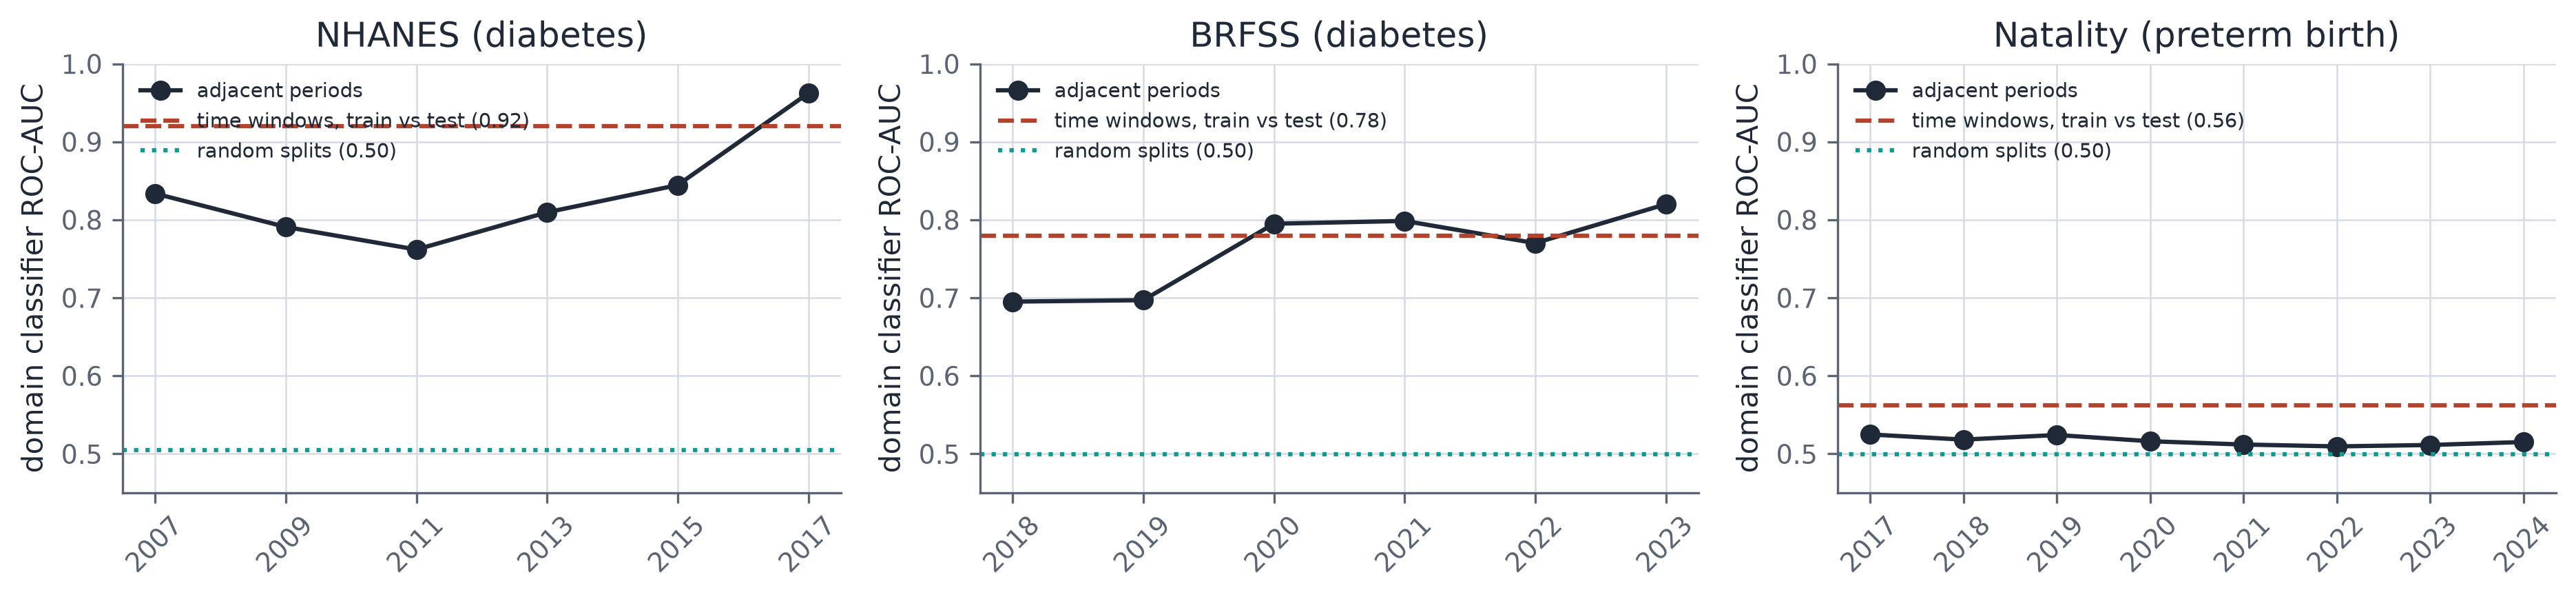

Covariate shift: ROC-AUC of a classifier telling two periods apart (0.5 = indistinguishable). Points: each period vs the previous one (x = later period).


In [41]:
# --- from scripts/make_figures.py ---
def fig_domain():
    dss = present("drift_domain.csv")
    fig, axes = panels(len(dss), 3.0)
    for ax, ds in zip(axes, dss):
        d = pd.read_csv(res(ds, "drift_domain.csv"))
        adj = d[d["kind"] == "adjacent"]
        ax.plot(range(len(adj)), adj["roc_auc"], marker="o", color=INK, label="adjacent periods")
        ax.set_xticks(range(len(adj)), [c.split(" vs ")[1][:4] for c in adj["comparison"]], rotation=45)
        tw = d[(d["kind"] == "time") & d["split"].str.startswith("sliding")]["roc_auc"].mean()
        rw = d[d["kind"] == "random"]["roc_auc"].mean()
        ax.axhline(tw, color=MODEL_COLORS["lightgbm"], ls="--", label=f"time windows, train vs test ({tw:.2f})")
        ax.axhline(rw, color=MODEL_COLORS["xgboost"], ls=":", label=f"random splits ({rw:.2f})")
        ax.set_ylim(0.45, 1.0); ax.set_title(NAMES[ds]); ax.set_ylabel("domain classifier ROC-AUC")
        ax.legend(fontsize=7, loc="upper left")
    fig.tight_layout()
    save(fig, "fig07_domain_shift",
         "Covariate shift: ROC-AUC of a classifier telling two periods apart (0.5 = indistinguishable). "
         "Points: each period vs the previous one (x = later period).")


fig_domain()
show("fig07_domain_shift")

Time splits are easy to tell apart in NHANES (0.86-0.97) and BRFSS (0.76-0.79), hardly in natality
(0.55-0.59); random splits are at 0.50 as expected.

### 10.2 Features with the largest drift (first vs last period)

In [42]:
for ds in DATASETS:
    f = pd.read_csv(ROOT / DATASETS[ds]["out"] / "drift_features.csv")
    print(ds); display(f.head(8)[["feature", "type", "drift_score", "ks", "psi", "tvd", "missing_first",
                                  "missing_last", "max_step", "max_step_between"]].round(3))

nhanes


,feature,type,drift_score,ks,psi,tvd,missing_first,missing_last,max_step,max_step_between
0,SMD100TR,numeric,1.781,0.246,1.781,NaN,0.809,0.874,1.402,2011-2012->2013-2014
1,LBXRDW,numeric,1.505,0.460,1.505,NaN,0.055,0.046,0.846,2011-2012->2013-2014
2,LBXSLDSI,numeric,1.167,0.429,1.167,NaN,0.080,0.088,1.156,2015-2016->2017-2018
3,LBXSTB,numeric,1.127,0.425,1.127,NaN,0.065,0.067,0.216,2015-2016->2017-2018
4,LBXSCLSI,numeric,0.919,0.401,0.919,NaN,0.065,0.067,0.651,2015-2016->2017-2018
5,SMD100CO,numeric,0.689,0.173,0.689,NaN,0.809,0.874,0.970,2011-2012->2013-2014
6,LBXSASSI,numeric,0.520,0.292,0.520,NaN,0.080,0.070,0.508,2015-2016->2017-2018
7,LBXBAPCT,numeric,0.506,0.237,0.506,NaN,0.060,0.046,0.518,2011-2012->2013-2014


brfss


,feature,type,drift_score,ks,psi,tvd,missing_first,missing_last,max_step,max_step_between
0,_INCOMG,categorical,0.283,NaN,NaN,0.283,0.165,0.000,0.251,2020->2021
1,INCOME,categorical,0.283,NaN,NaN,0.283,0.165,0.000,0.251,2020->2021
2,PERSDOC,categorical,0.256,NaN,NaN,0.256,0.004,0.010,0.220,2020->2021
3,MSCODE,categorical,0.231,NaN,NaN,0.231,0.574,0.805,0.056,2017->2018
4,TRNSGNDR,categorical,0.212,NaN,NaN,0.212,0.554,0.342,0.087,2017->2018
5,LASTSMK2,categorical,0.155,NaN,NaN,0.155,0.729,0.884,0.142,2020->2021
6,_STATE,categorical,0.145,NaN,NaN,0.145,0.000,0.000,0.130,2021->2022
7,LCSLAST,numeric,0.125,0.148,0.125,NaN,0.950,0.985,0.041,2021->2022


natality


,feature,type,drift_score,ks,psi,tvd,missing_first,missing_last,max_step,max_step_between
0,DMAR,categorical,0.110,NaN,NaN,0.110,0.000,0.110,0.121,2016->2017
1,BMI_R,categorical,0.082,NaN,NaN,0.082,0.027,0.023,0.017,2017->2018
2,WIC,categorical,0.080,NaN,NaN,0.080,0.012,0.012,0.025,2017->2018
3,NO_RISKS,categorical,0.072,NaN,NaN,0.072,0.001,0.001,0.016,2017->2018
4,MEDUC,categorical,0.071,NaN,NaN,0.071,0.013,0.018,0.014,2020->2021
5,MAGER9,categorical,0.068,NaN,NaN,0.068,0.000,0.000,0.017,2020->2021
6,MAGER14,categorical,0.068,NaN,NaN,0.068,0.000,0.000,0.017,2020->2021
7,CIG0_R,categorical,0.063,NaN,NaN,0.063,0.005,0.004,0.015,2020->2021


## 11. Results and comparison

### 11.1 Random vs time splits (TabReD's comparison)
For each sliding window and model: test ROC-AUC under the random split minus under the time split,
with a 95% unpaired bootstrap CI. Positive = the random split looks better than what the model
achieves on the future period.

In [43]:
# --- from scripts/summarize_benchmarks.py ---
def random_vs_time_tables(present) -> tuple[pd.DataFrame, pd.DataFrame]:
    """TabReD comparison: per window (gaps) and mean over windows with the model ranks."""
    gaps = pd.concat([read(ds, "random_minus_time_by_window.csv") for ds in present], ignore_index=True)
    gaps = gaps[gaps["metric"] == "roc_auc"]
    mean = gaps.groupby(["dataset", "model"])[["time", "random", "diff"]].mean().reset_index()
    mean["windows_significant"] = gaps.groupby(["dataset", "model"])["ci_excludes_zero"].sum().values
    mean["rank_time"] = mean.groupby("dataset")["time"].rank(ascending=False).astype(int)
    mean["rank_random"] = mean.groupby("dataset")["random"].rank(ascending=False).astype(int)
    mean = mean.rename(columns={"diff": "random_minus_time"}).sort_values(["dataset", "rank_time"])
    return gaps, mean


gaps, rvt = random_vs_time_tables(ALL_DS)
rvt.to_csv(SUMMARY_DIR / "random_vs_time.csv", index=False)
display(rvt.round(4))

,dataset,model,time,random,random_minus_time,windows_significant,rank_time,rank_random
0,brfss,lightgbm,0.8263,0.8334,0.0071,2,1,1
4,brfss,xgboost,0.8259,0.8330,0.0071,2,2,2
2,brfss,mlp,0.8240,0.8314,0.0074,2,3,3
1,brfss,logreg,0.8224,0.8296,0.0072,2,4,4
3,brfss,random_forest,0.8221,0.8285,0.0064,1,5,5
9,natality,xgboost,0.7533,0.7473,-0.0060,1,1,2
5,natality,lightgbm,0.7532,0.7487,-0.0045,1,2,1
7,natality,mlp,0.7470,0.7410,-0.0060,1,3,5
6,natality,logreg,0.7465,0.7427,-0.0038,0,4,3
8,natality,random_forest,0.7454,0.7421,-0.0033,0,5,4


saved fig03_random_minus_time


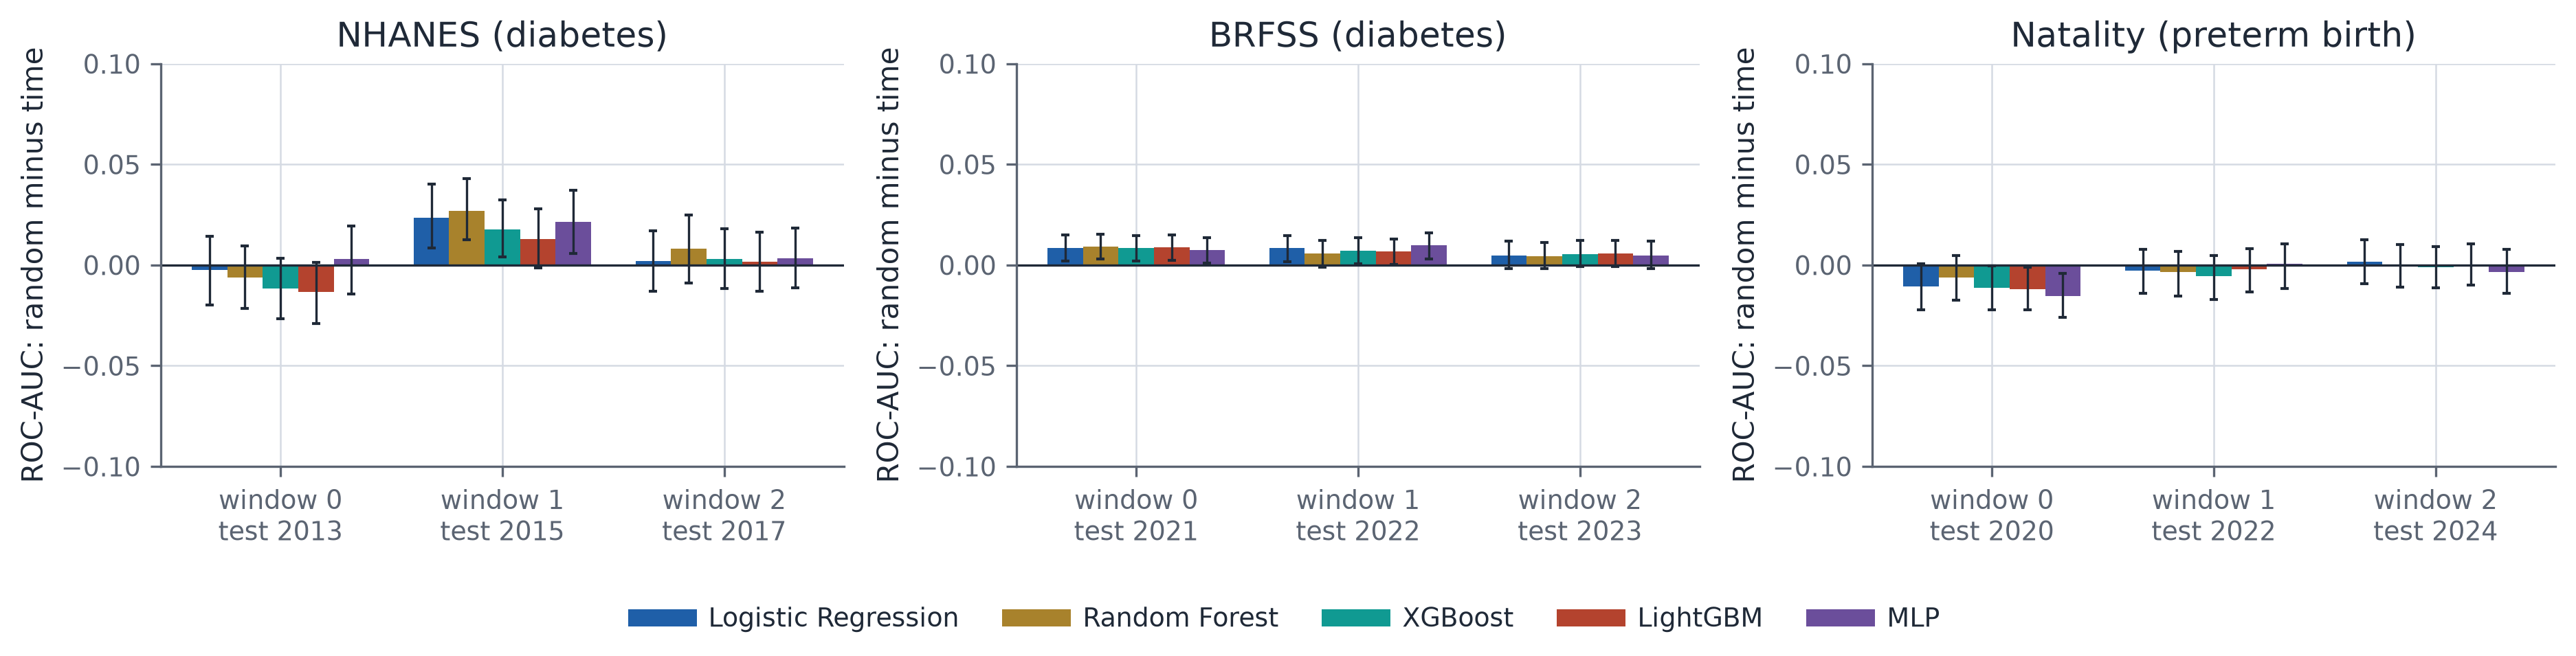

Random-split minus time-split test ROC-AUC per sliding window and model (95% bootstrap CI). Positive values: a random split overestimates performance on future data.


In [44]:
# --- from scripts/make_figures.py ---
def fig_random_vs_time():
    dss = present("random_minus_time_by_window.csv")
    fig, axes = panels(len(dss), 3.2)
    for ax, ds in zip(axes, dss):
        g = pd.read_csv(res(ds, "random_minus_time_by_window.csv"))
        g = g[g["metric"] == "roc_auc"]
        windows = sorted(g["window"].unique())
        width = 0.16
        test = [DATASETS[ds]["periods"][s + 4] for s in DATASETS[ds]["windows"]]
        for i, m in enumerate(MODELS):
            r = g[g["model"] == m].set_index("window").reindex(windows)
            x = np.arange(len(windows)) + (i - 2) * width
            ax.bar(x, r["diff"], width, color=MODEL_COLORS[m])
            ax.errorbar(x, r["diff"], yerr=[r["diff"] - r["diff_low"], r["diff_high"] - r["diff"]],
                        fmt="none", ecolor=INK, lw=0.8, capsize=1.5)
        ax.axhline(0, color=INK, lw=0.8)
        ax.set_xticks(range(len(windows)), [f"window {w}\ntest {str(t)[:4]}" for w, t in zip(windows, test)])
        ax.set_title(NAMES[ds]); ax.set_ylabel("ROC-AUC: random minus time")
        diff_axis(ax)
    model_legend(fig)
    save(fig, "fig03_random_minus_time",
         "Random-split minus time-split test ROC-AUC per sliding window and model (95% bootstrap CI). "
         "Positive values: a random split overestimates performance on future data.")


fig_random_vs_time()
show("fig03_random_minus_time")

* **NHANES:** random splits overestimate in window 1 (test 2015-16: +0.02, significant for 4 of 5
  models) and **change the ranking**: the MLP is 2nd under random splits but 4th under time splits.
* **BRFSS:** a small but consistent overestimation (+0.006 to +0.007 for all models; significant in
  9 of 15 model-windows: the test years 2021 and 2022).
* **Natality:** the opposite: time splits look *better* (-0.003 to -0.006). Section 11.2 explains why.

### 11.2 Random vs time on the same test period (new analysis)
TabReD's random and time test sets contain **different periods**: the random test set mixes all
periods of the window, the time test set is the last period only. If later periods are intrinsically
easier or harder, that alone changes the difference. We therefore also score the random-split model
**only on its test rows from the time split's test period**.

In [45]:
# --- from scripts/summarize_benchmarks.py ---
def load_predictions(ds: str) -> pd.DataFrame:
    path = ROOT / DATASETS[ds]["out"] / "predictions" / "test_predictions.csv"
    if not path.exists():   # large prediction files are stored gzipped in git
        path = path.with_name(path.name + ".gz")
    return pd.read_csv(path, dtype={"cycle": str})


def same_period_table(present, n_resamples: int = 1000, confidence: float = 0.95, seed: int = 42) -> pd.DataFrame:
    """Random vs time scored on the SAME period.

    TabReD's random and time test sets contain different periods, so their difference mixes
    "the model never saw this period" with "this period is easier/harder". Here the random split
    is scored only on its rows from the time split's test period.
    """
    rows = []
    for ds in present:
        p = load_predictions(ds)
        for k, start in enumerate(DATASETS[ds]["windows"]):
            period = DATASETS[ds]["periods"][start + 4]
            for m in MODELS:
                a = p[(p["protocol"] == f"random-{k}") & (p["model"] == m) & (p["cycle"] == period)]
                b = p[(p["protocol"] == f"sliding-window-{k}") & (p["model"] == m)]
                if a.empty or b.empty:
                    continue
                r = unpaired_difference(a["label"].to_numpy(), a["probability"].to_numpy(),
                                        b["label"].to_numpy(), b["probability"].to_numpy(),
                                        roc_auc_score, n_resamples, confidence, seed)
                rows.append({"dataset": ds, "window": k, "test_period": period, "model": m,
                             "random_same_period": roc_auc_score(a["label"], a["probability"]),
                             "time": roc_auc_score(b["label"], b["probability"]),
                             "n_random_rows": len(a), **r,
                             "ci_excludes_zero": r["diff_low"] > 0 or r["diff_high"] < 0})
    return pd.DataFrame(rows)


def same_period_mean(same: pd.DataFrame) -> pd.DataFrame:
    smean = same.groupby(["dataset", "model"])[["time", "random_same_period", "diff"]].mean().reset_index()
    smean["windows_significant"] = same.groupby(["dataset", "model"])["ci_excludes_zero"].sum().values
    return smean


same = same_period_table(ALL_DS, CONFIG["bootstrap"]["n_resamples"], CONFIG["bootstrap"]["confidence"], CONFIG["seed"])
same.to_csv(SUMMARY_DIR / "random_vs_time_same_period.csv", index=False)
display(same_period_mean(same).round(4))

,dataset,model,time,random_same_period,diff,windows_significant
0,brfss,lightgbm,0.8263,0.8305,0.0043,0
1,brfss,logreg,0.8224,0.8265,0.0041,0
2,brfss,mlp,0.8240,0.8286,0.0046,0
3,brfss,random_forest,0.8221,0.8277,0.0056,0
4,brfss,xgboost,0.8259,0.8296,0.0036,0
5,natality,lightgbm,0.7532,0.7499,-0.0033,0
6,natality,logreg,0.7465,0.7412,-0.0053,0
7,natality,mlp,0.7470,0.7424,-0.0046,0
8,natality,random_forest,0.7454,0.7433,-0.0021,0
9,natality,xgboost,0.7533,0.7481,-0.0052,0


saved fig10_random_minus_time_same_period


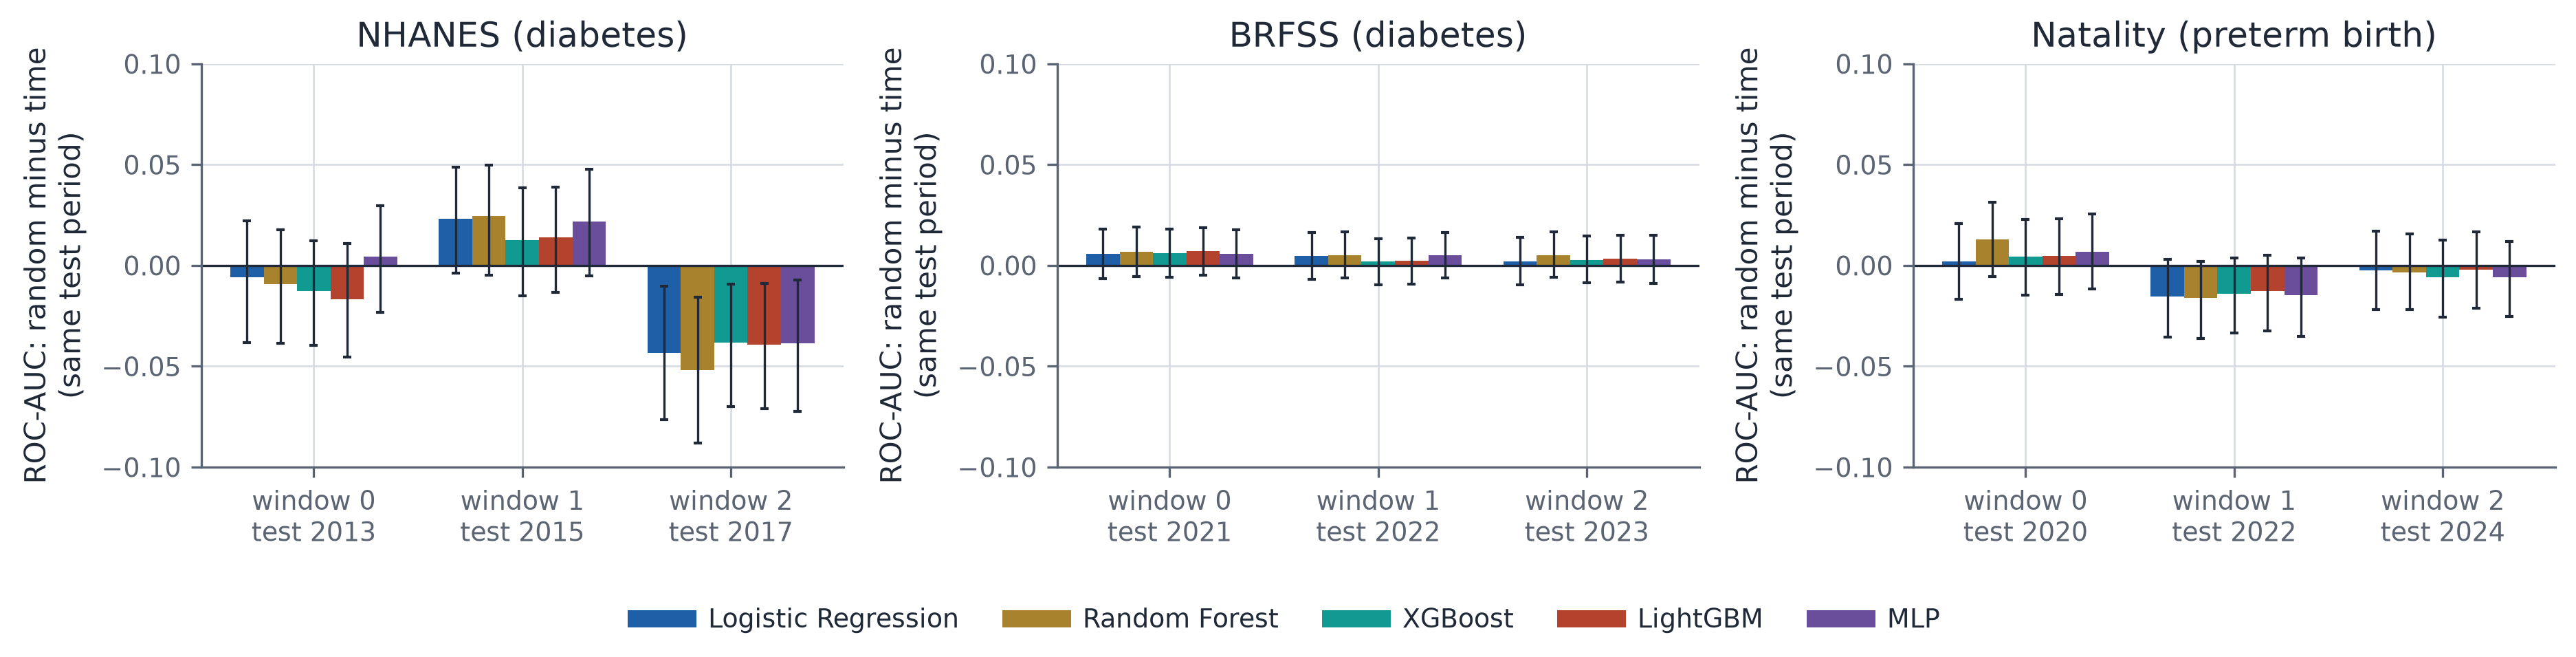

Random minus time ROC-AUC when both are scored on the SAME period (the time split's test period; random split restricted to its rows from that period), 95% bootstrap CI. Removes the effect of periods that are intrinsically easier or harder.


In [46]:
# --- from scripts/make_figures.py ---
def fig_same_period():
    path = SUMMARY_DIR / "random_vs_time_same_period.csv"
    if not path.exists():
        return
    same = pd.read_csv(path)
    dss = [ds for ds in DATASETS if ds in set(same["dataset"])]
    fig, axes = panels(len(dss), 3.2)
    for ax, ds in zip(axes, dss):
        g = same[same["dataset"] == ds]
        windows = sorted(g["window"].unique())
        width = 0.16
        for i, m in enumerate(MODELS):
            r = g[g["model"] == m].set_index("window").reindex(windows)
            x = np.arange(len(windows)) + (i - 2) * width
            ax.bar(x, r["diff"], width, color=MODEL_COLORS[m])
            ax.errorbar(x, r["diff"], yerr=[r["diff"] - r["diff_low"], r["diff_high"] - r["diff"]],
                        fmt="none", ecolor=INK, lw=0.8, capsize=1.5)
        ax.axhline(0, color=INK, lw=0.8)
        periods = g.drop_duplicates("window").set_index("window")["test_period"].reindex(windows)
        ax.set_xticks(range(len(windows)), [f"window {w}\ntest {str(t)[:4]}" for w, t in zip(windows, periods)])
        ax.set_title(NAMES[ds]); ax.set_ylabel("ROC-AUC: random minus time\n(same test period)")
        diff_axis(ax)
    model_legend(fig)
    save(fig, "fig10_random_minus_time_same_period",
         "Random minus time ROC-AUC when both are scored on the SAME period (the time split's test period; "
         "random split restricted to its rows from that period), 95% bootstrap CI. Removes the effect of "
         "periods that are intrinsically easier or harder.")


fig_same_period()
show("fig10_random_minus_time_same_period")

* **Natality:** on the same period the difference is small and never significant. Later years are
  simply more predictable (inside the random split's own test set, XGBoost's ROC-AUC rises from 0.735
  on 2016 rows to 0.761 on 2020 rows, as informative risk factors such as hypertension become more
  common). The "time looks better" result of 11.1 is a period-difficulty artefact: **no evidence
  that random splits overestimate for preterm birth.**
* **BRFSS:** on the same period the random split is higher in all 15 model-windows (+0.002 to
  +0.007; not significant individually with ~10,000 rows, but 15/15 with the same sign).
* **NHANES:** window 1 +0.012 to +0.025 (not significant, ~1,000 rows); in window 2 (2017-18) the
  pooled random-split model is significantly *worse* on 2017-18 respondents (about -0.04). A
  plausible, untested explanation is the 2017-18 laboratory analyzer change: pooling shifted and
  unshifted lab values in training makes the lab features less consistent.
* **Methodological point:** TabReD's comparison mixes "the model has not seen this period" with "this
  period is easier or harder"; the same-period comparison separates the two and changes the
  conclusion for natality.

### 11.3 TabReD Table 4: relative ROC-AUC improvement over the MLP (%)

In [47]:
# --- from scripts/summarize_benchmarks.py ---
def improvement_table(present, gaps: pd.DataFrame) -> pd.DataFrame:
    """TabReD Table 4 style: % ROC-AUC improvement over the MLP under time and random splits."""
    rows = []
    for ds in present:
        g = gaps[gaps["dataset"] == ds]
        for kind in ["time", "random"]:
            per = g.pivot_table(index="window", columns="model", values=kind)
            rel = ((per.sub(per["mlp"], axis=0)).div(per["mlp"], axis=0) * 100).mean()
            rows.append({"dataset": ds, "splits": kind, **{LABELS[m]: rel.get(m) for m in MODELS if m != "mlp"}})
    return pd.DataFrame(rows)


imp = improvement_table(ALL_DS, gaps)
imp.to_csv(SUMMARY_DIR / "improvement_over_mlp.csv", index=False)
display(imp.round(2))

,dataset,splits,Logistic Regression,Random Forest,XGBoost,LightGBM
0,nhanes,time,0.09,-2.00,0.97,0.99
1,nhanes,random,-0.08,-1.94,0.28,-0.00
2,brfss,time,-0.20,-0.23,0.24,0.28
3,brfss,random,-0.22,-0.35,0.19,0.24
4,natality,time,-0.07,-0.22,0.84,0.83
5,natality,random,0.23,0.15,0.85,1.03


TabReD found that XGBoost's lead over the MLP **shrinks** under time splits. Here it does not: it
grows in NHANES (+0.28% under random splits -> +0.97% under time splits) and stays about the same in
BRFSS (+0.19% -> +0.24%) and natality (+0.85% -> +0.84%). In this clinical data the GBDT advantage is
hidden by random splits rather than inflated by them. (Our MLP is scikit-learn's, not TabReD's tuned
MLP / MLP-PLR.)

### 11.4 Does drift explain the performance gaps?
One row per sliding window: domain-classifier AUC, prevalence change and documented events of the
test period next to the random-minus-time gap.

In [48]:
perf = pd.concat([pd.read_csv(ROOT / DATASETS[ds]["out"] / "drift_performance.csv").assign(dataset=ds)
                  for ds in DATASETS], ignore_index=True)
perf.to_csv(SUMMARY_DIR / "drift_performance.csv", index=False)
display(perf[["dataset", "window", "test", "domain_auc_time", "prevalence_train", "prevalence_test",
              "random_minus_time_mean", "models_gap_significant", "events_in_test_period"]].round(3))

,dataset,window,test,domain_auc_time,prevalence_train,prevalence_test,random_minus_time_mean,models_gap_significant,events_in_test_period
0,nhanes,0,2013-2014,0.864,0.119,0.131,-0.006,0,Hematology analyzer replaced by Beckman Coulter DxH 800; CDC: mean RDW 12.84% -> 13.55...
1,nhanes,1,2015-2016,0.921,0.126,0.151,0.020,4,Not covered by health insurance: falls after the 2014 Affordable Care Act coverage exp...
2,nhanes,2,2017-2018,0.974,0.127,0.164,0.004,0,Biochemistry analyzer and lab changed to Roche Cobas 6000; CDC bridging study: LDH +14...
3,brfss,0,2021,0.790,0.138,0.132,0.008,5,PERSDOC2 -> PERSDOC3 rewording: 'more than one personal doctor' jumps | Yes/no coverag...
4,brfss,1,2022,0.784,0.136,0.136,0.008,4,2022 race question: 'other race only' category removed
5,brfss,2,2023,0.766,0.133,0.139,0.005,0,NaN
6,natality,0,2020,0.570,0.098,0.103,-0.011,3,Hospital COVID-19 policies: more births with unknown father information (NCHS User Guide)
7,natality,1,2022,0.564,0.101,0.105,-0.003,0,NaN
8,natality,2,2024,0.552,0.105,0.105,-0.000,0,NaN


* **More covariate shift does not mean a bigger performance drop.** The strongest shift (NHANES
  2017-18, the laboratory analyzer change: domain AUC 0.97) causes no significant gap; the
  significant NHANES gap (2015-16) comes with a **label shift** (prevalence 12.6% -> 15.1%) and the
  ACA population change.
* **Coding revisions coincide with the gaps in BRFSS:** significant random-split optimism in the test
  years with questionnaire revisions (2021, 2022), none in 2023.
* **Natality** has little covariate shift and no random-split optimism.

### 11.5 Answer to the research questions

| TabReD claim | NHANES (280 features) | BRFSS (93) | Natality (73) |
|---|---|---|---|
| Random splits overestimate future performance | yes, in the label-shift window | yes, small but consistent, in coding-revision years | no (the apparent opposite is a period-difficulty artefact) |
| Random splits change the model ranking | yes (MLP 2nd -> 4th) | no | partly (MLP, LR; GBDTs stay on top) |
| GBDTs are the strongest models | yes | yes | yes |
| XGBoost's lead over the MLP shrinks under time splits | no, it grows | no (similar) | no (same) |

All tables written by this notebook are in `notebooks/outputs/tables/`, the figures in
`notebooks/outputs/figures/` (the repository's `figures/` folder holds the same figures for the report).

In [49]:
print(sorted(p.name for p in SUMMARY_DIR.glob("*.csv")))
print(sorted(p.name for p in FIGURES_DIR.glob("*.png")))

['cv_summary.csv', 'default_paired_comparisons.csv', 'default_test_metrics.csv', 'drift_events_brfss.csv', 'drift_events_natality.csv', 'drift_events_nhanes.csv', 'drift_performance.csv', 'improvement_over_mlp.csv', 'leakage_audit_brfss.csv', 'leakage_audit_natality.csv', 'leakage_audit_nhanes.csv', 'random_vs_time.csv', 'random_vs_time_same_period.csv', 'reproduction_check.csv', 'splits_brfss.csv', 'splits_natality.csv', 'splits_nhanes.csv', 'test_roc_auc_by_split.csv']
['fig01_prevalence.png', 'fig02_default_auc_ci.png', 'fig03_random_minus_time.png', 'fig04_roc_curves.png', 'fig05_confusion_matrices.png', 'fig06_mlp_training_curves.png', 'fig07_domain_shift.png', 'fig08_drift_events.png', 'fig09_cross_validation.png', 'fig10_random_minus_time_same_period.png']


## 12. Limitations and conclusion

### Limitations
* **One seed and small grids** (TabReD: 15 seeds and 100 Optuna trials); significance is judged with
  bootstrap CIs instead.
* **Models:** no CatBoost and no MLP-PLR / FT-Transformer (TabReD's strongest deep models); the MLP
  is scikit-learn's.
* **Different rows in random and time test sets** (as in TabReD); the same-period analysis uses about
  1,000 (NHANES) or 10,000 (BRFSS, natality) random-split rows per window, so its CIs are wide.
* **Feature counts** of BRFSS (93) and natality (73) are below TabReD's range; they were not padded
  with derived features.
* **Causal explanations** (laboratory instruments for NHANES 2017-18, risk-factor prevalence for
  natality) are hypotheses consistent with the data, not tested causally.
* **Survey data:** models are trained without survey weights; NHANES and BRFSS sample different people
  in each period; the NHANES and BRFSS labels are self-reported diagnoses (undiagnosed diabetes
  counts as negative).
* This is an educational benchmark, not a validated clinical prediction system.

### Conclusion
Gradient-boosted trees are the best models on all three clinical datasets, with or without temporal
shift. Random splits overestimate performance on future periods and reorder the models in the
feature-rich NHANES data, slightly overestimate it in BRFSS, and do not overestimate it for preterm
birth. Whether a random split misleads depends on the **type** of drift (label shift and
questionnaire coding revisions matter; measurement-instrument changes and smooth trends matter less)
rather than on how large the covariate shift is. Comparing random and time splits on the same test
period is necessary to separate temporal shift from differences in how hard each period is.

### References
1. I. Rubachev, N. Kartashev, Y. Gorishniy, A. Babenko, "TabReD: Analyzing Pitfalls and Filling the
   Gaps in Tabular Deep Learning Benchmarks," arXiv:2406.19380, 2024.
2. CDC / NCHS, National Health and Nutrition Examination Survey, https://wwwn.cdc.gov/nchs/nhanes/.
3. CDC, Behavioral Risk Factor Surveillance System, https://www.cdc.gov/brfss/annual_data/annual_data.htm.
4. CDC / NCHS, Vital Statistics Natality Birth Data and User Guides,
   https://www.cdc.gov/nchs/data_access/vitalstatsonline.htm.
5. F. Pedregosa et al., "Scikit-learn: Machine Learning in Python," JMLR 12, 2011.
6. T. Chen, C. Guestrin, "XGBoost: A Scalable Tree Boosting System," KDD 2016.
7. G. Ke et al., "LightGBM: A Highly Efficient Gradient Boosting Decision Tree," NeurIPS 2017.
8. S. Rabanser, S. Günnemann, Z. C. Lipton, "Failing Loudly: An Empirical Study of Methods for
   Detecting Dataset Shift," NeurIPS 2019.